In [1]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.ndimage import gaussian_filter
import imageio.v2 as imageio

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    HAS_CARTOPY = True
except ImportError:
    HAS_CARTOPY = False

os.makedirs('figures', exist_ok=True)   # experiment figures are saved here

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12

In [2]:
from matplotlib.collections import LineCollection

STATE_LINES = []
if HAS_CARTOPY:
    try:
        for g in cfeature.STATES.geometries():
            b = g.boundary
            for part in getattr(b, "geoms", [b]):
                STATE_LINES.append(np.asarray(part.coords)[:, :2])
    except Exception as e:
        print("Could not load state outlines (", type(e).__name__, ") - plots will have no state borders.")
print("state border segments loaded:", len(STATE_LINES))

def add_states(ax, color="0.25", lw=0.4):
    """Draw state borders on a plain lon/lat axes without changing its limits."""
    if STATE_LINES:
        xl, yl = ax.get_xlim(), ax.get_ylim()
        ax.add_collection(LineCollection(STATE_LINES, colors=color, linewidths=lw, zorder=3))
        ax.set_xlim(xl); ax.set_ylim(yl)
    return ax

state border segments loaded: 60


# The gridMET Dataset

Dataset:
gridMET Daily Meteorological Dataset

Variable:
Daily Maximum Air Temperature (tmmx)

Selected Period:
July – September 2021

**Rationale.** The Jul-Sep slice contains the seasonal maximum and the start of autumn cooling. Nine dates are sampled uniformly (every 11-12 days, both endpoints), which covers the season without bias; event-based dates are discussed below but not used for the final maps. *Confirm that this slice is the one assigned to the team.*

**Algorithm.** Contour lines (`contour`) and filled contours (`contourf`) use a marching-squares-type algorithm. A from-scratch marching squares implementation is added at the end of the notebook and checked against Matplotlib.

In [3]:
path = "data/tmmx_2021.nc"

ds = xr.open_dataset(path)

ds

<xarray.Dataset> Size: 2GB
Dimensions:          (day: 365, lat: 585, lon: 1386, crs: 1)
Coordinates:
  * day              (day) datetime64[ns] 3kB 2021-01-01 ... 2021-12-31
  * lat              (lat) float64 5kB 49.4 49.36 49.32 ... 25.15 25.11 25.07
  * lon              (lon) float64 11kB -124.8 -124.7 -124.7 ... -67.1 -67.06
  * crs              (crs) uint16 2B 3
Data variables:
    air_temperature  (day, lat, lon) float64 2GB ...
Attributes: (12/19)
    geospatial_bounds_crs:      EPSG:4326
    Conventions:                CF-1.6
    geospatial_bounds:          POLYGON((-124.7666666333333 49.40000000000000...
    geospatial_lat_min:         25.066666666666666
    geospatial_lat_max:         49.40000000000000
    geospatial_lon_min:         -124.7666666333333
    ...                         ...
    date:                       30 March 2023
    note1:                      The projection information for this file is: ...
    note2:                      Citation: Abatzoglou, J.T., 2013, Development...
    note3:                      Data in slices after last_permanent_slice (1-...
    note4:                      Data in slices after last_provisional_slice (...
    note5:                      Days correspond approximately to calendar day...

In [4]:
print(ds.sizes)
print(ds.coords)
print(ds.data_vars)
print(ds.attrs)

t = ds["air_temperature"]

print(t.attrs)
print(ds.day.values[0])
print(ds.day.values[-1])


Frozen({'day': 365, 'lat': 585, 'lon': 1386, 'crs': 1})
Coordinates:
  * day      (day) datetime64[ns] 3kB 2021-01-01 2021-01-02 ... 2021-12-31
  * lat      (lat) float64 5kB 49.4 49.36 49.32 49.28 ... 25.15 25.11 25.07
  * lon      (lon) float64 11kB -124.8 -124.7 -124.7 ... -67.14 -67.1 -67.06
  * crs      (crs) uint16 2B 3
Data variables:
    air_temperature  (day, lat, lon) float64 2GB ...
{'geospatial_bounds_crs': 'EPSG:4326', 'Conventions': 'CF-1.6', 'geospatial_bounds': 'POLYGON((-124.7666666333333 49.400000000000000, -124.7666666333333 25.066666666666666, -67.058333300000015 25.066666666666666, -67.058333300000015 49.400000000000000, -124.7666666333333 49.400000000000000))', 'geospatial_lat_min': '25.066666666666666', 'geospatial_lat_max': '49.40000000000000', 'geospatial_lon_min': '-124.7666666333333', 'geospatial_lon_max': '-67.058333300000015', 'geospatial_lon_resolution': '0.041666666666666', 'geospatial_lat_resolution': '0.041666666666666', 'geospatial_lat_units': 'decimal

In [5]:
summer = ds.sel(
    day=slice("2021-07-01", "2021-09-30")
)

# summer
print(summer.sizes)
temp = summer["air_temperature"]

temp

Frozen({'day': 92, 'lat': 585, 'lon': 1386, 'crs': 1})


<xarray.DataArray 'air_temperature' (day: 92, lat: 585, lon: 1386)> Size: 597MB
[74594520 values with dtype=float64]
Coordinates:
  * day      (day) datetime64[ns] 736B 2021-07-01 2021-07-02 ... 2021-09-30
  * lat      (lat) float64 5kB 49.4 49.36 49.32 49.28 ... 25.15 25.11 25.07
  * lon      (lon) float64 11kB -124.8 -124.7 -124.7 ... -67.14 -67.1 -67.06
Attributes:
    units:              K
    description:        Daily Maximum Temperature
    long_name:          tmmx
    standard_name:      tmmx
    dimensions:         lon lat time
    grid_mapping:       crs
    coordinate_system:  WGS84,EPSG:4326

In [6]:
print(temp.shape)

temp_c = temp - 273.15
temp_c.attrs["units"] = "degC"  
# subtraction keeps the old 'K' attribute, so reset it
print("Minimum :", float(temp_c.min()))
print("Maximum :", float(temp_c.max()))
print("Mean    :", float(temp_c.mean()))
print("Std     :", float(temp_c.std()))

(92, 585, 1386)
Minimum : -8.25
Maximum : 54.150000000000034
Mean    : 29.0161048526595
Std     : 5.451529301251525


**What this shows:** the season's daily maximum temperature has a mean of about 29 °C and a standard deviation of about 5.5 °C over all grid cells and days. The minimum of about -8 °C comes from high mountain cells and the maximum of about 54 °C from the desert Southwest. All later maps use temperature in °C, not Kelvin.

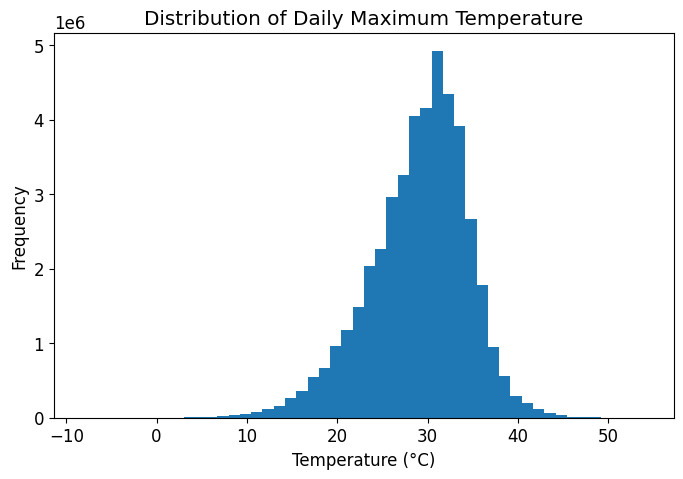

In [7]:
vals = temp_c.values.ravel()
vals = vals[~np.isnan(vals)]

plt.figure(figsize=(8, 5))
plt.hist(vals, bins=50)
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.title("Distribution of Daily Maximum Temperature")
plt.show()

**Reading the histogram:** a single peak near 30-31 °C with a longer tail towards cold values (left-skewed). Most grid cell-days sit between 23 and 36 °C. Values above 40 °C are rare and come only from the hottest desert cells. The cold tail comes from high mountains and late-September days. A single colour scale for the whole season has to cover about -8 to 54 °C even though most data lies between 20 and 40 °C. This is why the final levels are limited to 10-50 °C, with `extend="both"` for the outliers.

In [8]:
day1 = temp_c.isel(day=0)
print(day1.shape)
lat = ds.lat
lon = ds.lon
print(lat.shape)
print(lon.shape)

(585, 1386)
(585,)
(1386,)


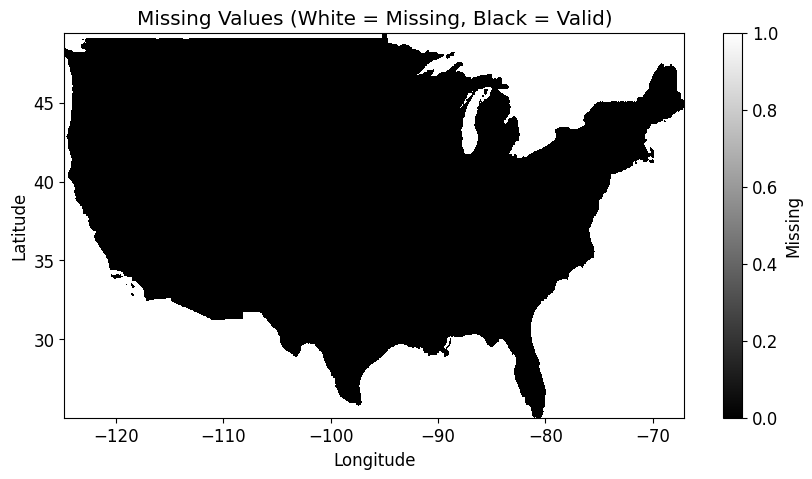

In [9]:
mask = np.isnan(day1)

plt.figure(figsize=(10, 5))
plt.pcolormesh(ds.lon, ds.lat, mask, shading="auto", cmap="gray")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Missing Values (White = Missing, Black = Valid)")
plt.colorbar(label="Missing")
plt.show()

**Reading the mask:** valid cells (black) cover land inside the contiguous US. Ocean, the Great Lakes and areas outside the US are NaN. Contours are therefore drawn only over land. The mask is the same on every day, so a NaN-aware smoothing (used later) only needs to handle the coastline.

In [10]:
# Average temperature over the entire spatial domain for each day
daily_mean = temp_c.mean(dim=["lat", "lon"])
daily_mean.attrs["units"] = "degC"

print(daily_mean.shape)
daily_mean  

(92,)


<xarray.DataArray 'air_temperature' (day: 92)> Size: 736B
array([29.45992273, 29.20954381, 30.09012057, 30.85142556, 30.89032227,
       30.19581662, 29.43218997, 29.85717535, 30.59374999, 30.47473201,
       30.19289523, 30.27853875, 30.15023725, 29.8090472 , 30.26185813,
       30.27263314, 30.68138264, 30.77474379, 30.1616091 , 29.68886033,
       29.68427386, 30.54283478, 30.97010833, 31.3353546 , 31.77097074,
       32.09782931, 32.06293237, 31.91350059, 31.26254239, 30.54835847,
       29.68939208, 28.69628492, 28.85662728, 29.37105795, 29.8327802 ,
       29.86450259, 29.79175465, 30.01368803, 30.50332221, 30.46339095,
       31.4331803 , 32.0871163 , 31.41873867, 30.81295913, 30.9884623 ,
       30.67001471, 30.54692402, 29.16552744, 27.42329229, 27.31168298,
       27.60676956, 27.25777302, 28.49881179, 30.20872605, 30.36108976,
       30.263076  , 29.70047233, 29.41966928, 29.46439926, 29.48290409,
       29.62297279, 28.53839999, 27.13318319, 26.44409997, 26.49768176,
       27.85273167, 28.81276156, 30.05293999, 30.07195756, 29.24052614,
       29.20859213, 28.84192794, 28.06928871, 28.03780708, 27.64108579,
       27.52466929, 27.54346924, 26.77789644, 26.81813418, 27.76536624,
       26.3291948 , 24.4914242 , 24.1293839 , 24.74200792, 24.29353464,
       24.66066196, 26.09735647, 27.12295543, 27.12891518, 25.14905328,
       23.17801237, 22.94375464])
Coordinates:
  * day      (day) datetime64[ns] 736B 2021-07-01 2021-07-02 ... 2021-09-30
Attributes:
    units:              degC
    description:        Daily Maximum Temperature
    long_name:          tmmx
    standard_name:      tmmx
    dimensions:         lon lat time
    grid_mapping:       crs
    coordinate_system:  WGS84,EPSG:4326

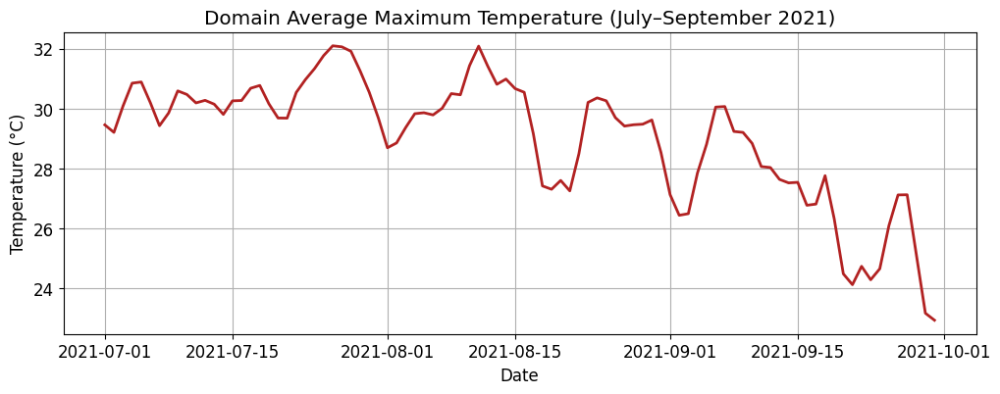

In [11]:
plt.figure(figsize=(12,4))

plt.plot(
    daily_mean.day,
    daily_mean,
    color="firebrick",
    linewidth=2
)

plt.title("Domain Average Maximum Temperature (July–September 2021)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True)

plt.gcf().savefig('figures/domain_mean.png', dpi=200, bbox_inches='tight')
plt.show()

**What this shows:** the domain-average daily maximum falls from about 30 °C in July to about 23 °C at the end of September, which is the seasonal cooling. There are two heat peaks of about 32 °C, around Jul 26 and Aug 11. Sharp drops (mid-Aug, early Sep, late Sep) are most likely cold fronts passing across large parts of the country. Note that a domain average hides *where* the heat is. This is the question the contour maps answer.

In [12]:
# Select 9 approximately equally spaced dates

uniform_idx = np.linspace(0, len(daily_mean)-1, 9, dtype=int)

uniform_dates = daily_mean.day.values[uniform_idx]
uniform_temp = daily_mean.values[uniform_idx]

print(uniform_dates)

['2021-07-01T00:00:00.000000000' '2021-07-12T00:00:00.000000000'
 '2021-07-23T00:00:00.000000000' '2021-08-04T00:00:00.000000000'
 '2021-08-15T00:00:00.000000000' '2021-08-26T00:00:00.000000000'
 '2021-09-07T00:00:00.000000000' '2021-09-18T00:00:00.000000000'
 '2021-09-30T00:00:00.000000000']


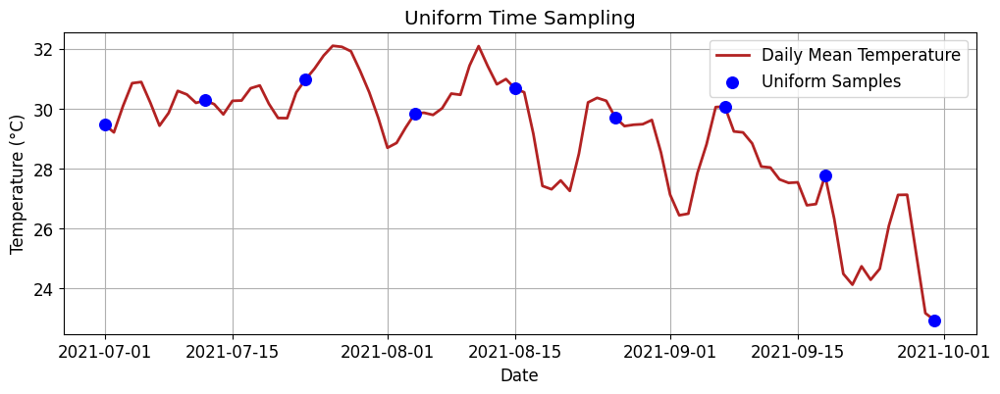

In [13]:
plt.figure(figsize=(12,4))

plt.plot(
    daily_mean.day,
    daily_mean,
    color="firebrick",
    linewidth=2,
    label="Daily Mean Temperature"
)

plt.scatter(
    uniform_dates,
    uniform_temp,
    color="blue",
    s=70,
    label="Uniform Samples",
    zorder=3
)

plt.title("Uniform Time Sampling")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.legend()

plt.gcf().savefig('figures/uniform_sampling.png', dpi=200, bbox_inches='tight')
plt.show()

**Uniform sampling** gives evenly spaced dates (about every 11-12 days), so the season is covered without bias. However, it can miss peaks and troughs because it does not look at the data.

In [14]:
event_dates = [
    "2021-07-01",
    "2021-07-15",
    "2021-07-26",   # heat peak (domain-mean maximum, 32.1 degC)
    "2021-08-10",
    "2021-08-20",
    "2021-08-30",   # Hurricane Ida
    "2021-09-05",
    "2021-09-15",
    "2021-09-30"
]

event_mean = daily_mean.sel(day=event_dates)

# check the claims against the data
print("Hottest day (domain mean):", str(daily_mean.idxmax("day").values)[:10], round(float(daily_mean.max()), 2), "degC")
print("Coolest day (domain mean):", str(daily_mean.idxmin("day").values)[:10], round(float(daily_mean.min()), 2), "degC")

Hottest day (domain mean): 2021-07-26 32.1 degC
Coolest day (domain mean): 2021-09-30 22.94 degC


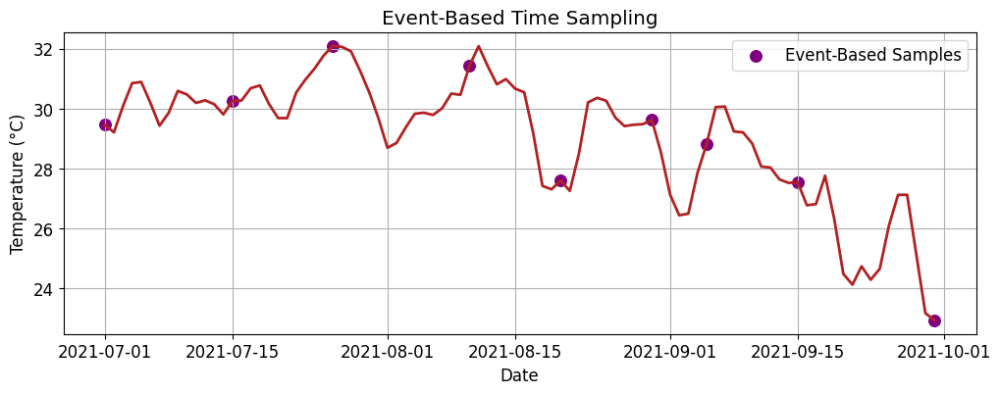

In [15]:
plt.figure(figsize=(12,4))

plt.plot(
    daily_mean.day,
    daily_mean,
    color="firebrick",
    linewidth=2
)

plt.scatter(
    event_mean.day,
    event_mean,
    color="purple",
    s=70,
    label="Event-Based Samples"
)

plt.title("Event-Based Time Sampling")

plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.grid(True)
plt.legend()

plt.gcf().savefig('figures/event_sampling.png', dpi=200, bbox_inches='tight')
plt.show()

**Event-based sampling** puts dates on the heat peak (Jul 26), the cool dips (Aug 20, Sep 30) and the transitions. It catches extremes that uniform sampling misses, and its picks are explained by the weather. A domain average cannot show a local event such as Hurricane Ida (Gulf Coast, ~Aug 29-30), so for such events the map matters more than the curve. The final maps below use the uniform dates for an unbiased seasonal sequence. The event dates are useful for extra maps.

In [16]:
# First sampled date
selected_date = uniform_dates[0]

print(selected_date)

2021-07-01T00:00:00.000000000


In [17]:
day = temp_c.sel(day=selected_date)

print(day.shape)

(585, 1386)


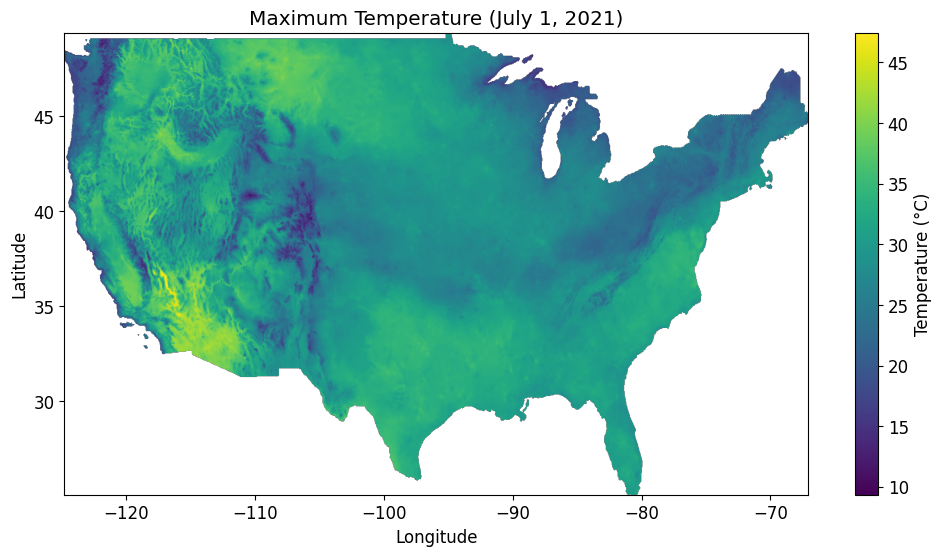

In [18]:
plt.figure(figsize=(12, 6))

# lat runs 49.4 -> 25.07, so row 0 is north: origin must be "upper".
# extent puts real lon/lat on the axes.
plt.imshow(
    day,
    origin="upper",
    extent=[float(lon.min()), float(lon.max()), float(lat.min()), float(lat.max())],
    cmap="viridis",
    aspect="auto"
)

plt.colorbar(label="Temperature (°C)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Maximum Temperature (July 1, 2021)")
plt.show()

**Raw image (no contours):** the hottest areas are the Southwest deserts and California's Central Valley, with a broad warm belt over the southern Plains. The Pacific coast, the Rockies and the northern tier are cooler. The colour change is smooth, so it is hard to read a value or see where a gradient is steep. Contour lines add exactly this.

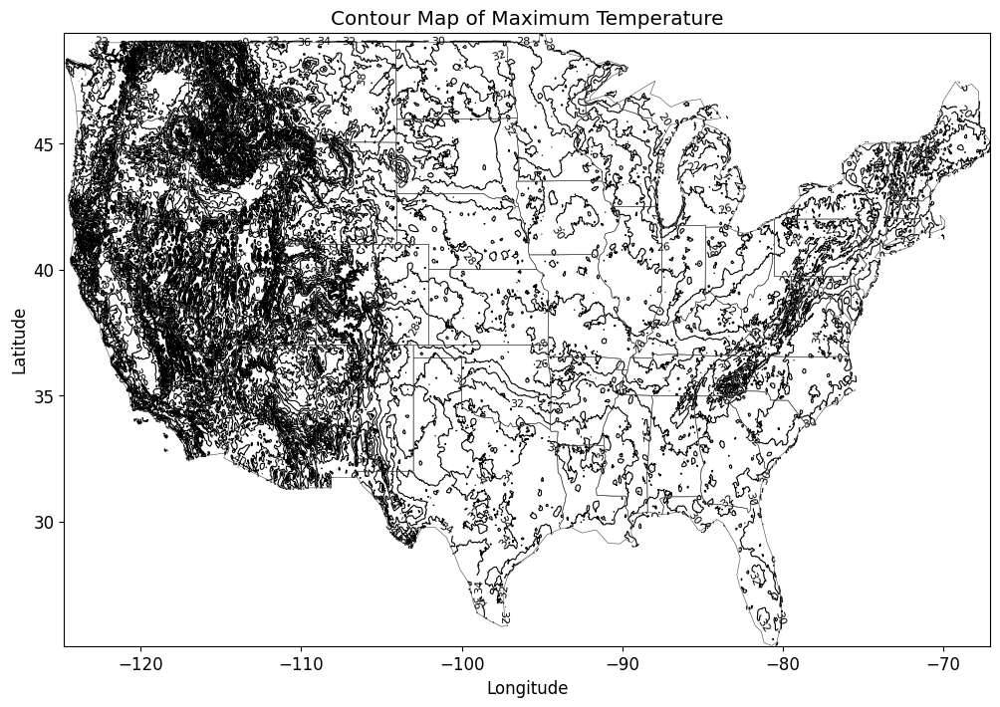

In [19]:
levels = np.arange(20,46,2)
plt.figure(figsize=(12,8))

contours = plt.contour(
    lon,
    lat,
    day,
    levels=levels,
    colors="black",
    linewidths=0.8
)

plt.clabel(contours,fontsize=8)
add_states(plt.gca())

plt.title("Contour Map of Maximum Temperature")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.gcf().savefig('figures/contour_lines.png', dpi=200, bbox_inches='tight')
plt.show()

**Reading the contour lines:** each line joins points with the same temperature, so the **spacing between lines is the gradient**. Lines packed close together (the mountainous West, the coast) mean temperature changes quickly over a short distance. This is mostly due to elevation. Widely spaced lines (Great Plains, Southeast) mean a flat, uniform temperature field. Closed rings mark local hot or cold spots.

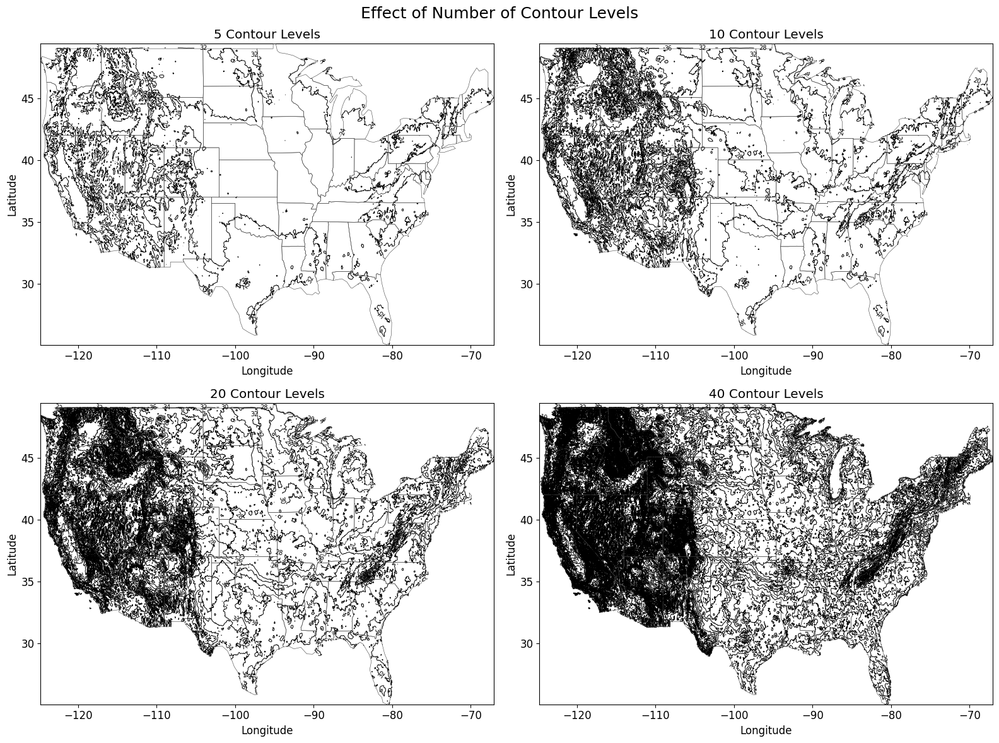

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

level_list = [5, 10, 20, 40]

for ax, n_levels in zip(axes.ravel(), level_list):

    contours = ax.contour(
        lon,
        lat,
        day,
        levels=n_levels,
        colors="black",
        linewidths=0.7
    )

    ax.clabel(contours, fontsize=7)

    add_states(ax)
    ax.set_title(f"{n_levels} Contour Levels")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.suptitle("Effect of Number of Contour Levels", fontsize=18)

plt.tight_layout()

plt.gcf().savefig('figures/level_count.png', dpi=200, bbox_inches='tight')
plt.show()

**Number of levels:** with 5 levels the map still shows many small closed loops over the western mountains, and from 20 levels upward the West is almost black and labels are unreadable. Every count therefore clutters the raw 4 km field. The final maps use a fine continuous fill with sparse labelled lines (every 5 °C) on a lightly smoothed field instead of dense lines.

In [21]:
equal_levels = np.linspace(
    float(day.min()),
    float(day.max()),
    20
)

print(equal_levels)

[ 9.35       11.35526316 13.36052632 15.36578947 17.37105263 19.37631579
 21.38157895 23.38684211 25.39210526 27.39736842 29.40263158 31.40789474
 33.41315789 35.41842105 37.42368421 39.42894737 41.43421053 43.43947368
 45.44473684 47.45      ]


In [22]:
valid = day.values[~np.isnan(day.values)]

# 20 quantile levels (np.unique guarantees strictly increasing levels, which contour() requires)
quantile_levels = np.unique(np.quantile(valid, np.linspace(0, 1, 20)))

print(quantile_levels)

[ 9.35 21.55 23.35 24.75 25.95 26.85 27.55 28.25 28.85 29.45 30.05 30.75
 31.35 31.95 32.55 33.15 33.75 34.55 36.45 47.45]


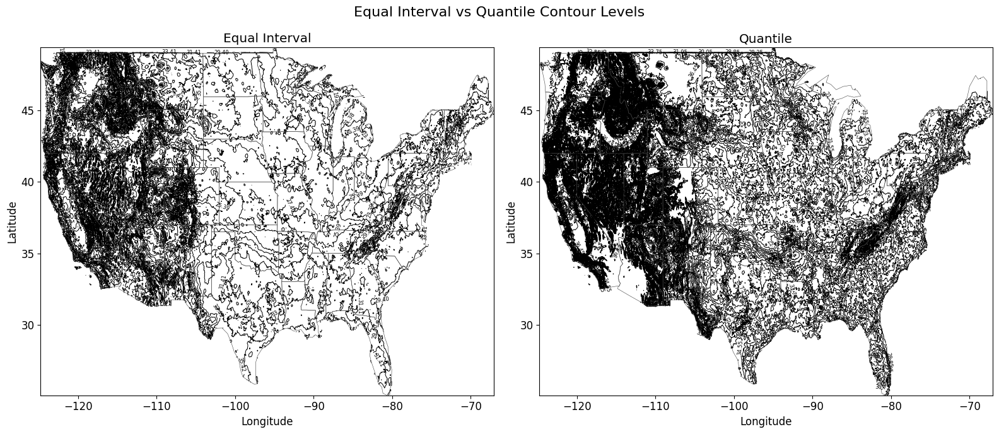

In [23]:
equal_levels = np.linspace(float(day.min()), float(day.max()), 20)

# Quantile levels
valid = day.values[~np.isnan(day.values)]
quantile_levels = np.unique(np.quantile(valid, np.linspace(0, 1, 20)))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

level_sets = [
    (equal_levels, "Equal Interval"),
    (quantile_levels, "Quantile")
]

for ax, (levels, title) in zip(axes, level_sets):
    cs = ax.contour(lon, lat, day, levels=levels, colors="black", linewidths=0.7)
    ax.clabel(cs, fontsize=6)
    add_states(ax)
    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.suptitle("Equal Interval vs Quantile Contour Levels", fontsize=16)
plt.tight_layout()
plt.gcf().savefig('figures/equal_vs_quantile.png', dpi=200, bbox_inches='tight')
plt.show()

 Equal-interval contour levels produce contours at constant temperature increments, making them
 suitable for quantitative interpretation of temperature gradients. Quantile-based contours allocate
 more contour levels within the most common temperature range (approximately 26–34°C), revealing subtle
 spatial variations but reducing the physical interpretability of contour spacing. Therefore, equal-interval
 contouring was selected for the final visualizations because it provides consistent and scientifically meaningful temperature  intervals.

In [24]:
global_min = float(temp_c.min())
global_max = float(temp_c.max())
print("Global Min:", global_min)
print("Global Max:", global_max)
global_levels = np.arange(10, 52, 2)
print(global_levels)

Global Min: -8.25
Global Max: 54.150000000000034
[10 12 14 16 18 20 22 24 26 28 30 32 34 36 38 40 42 44 46 48 50]


In [25]:
day_hot = temp_c.sel(day="2021-07-23")
day_cool = temp_c.sel(day="2021-09-30")

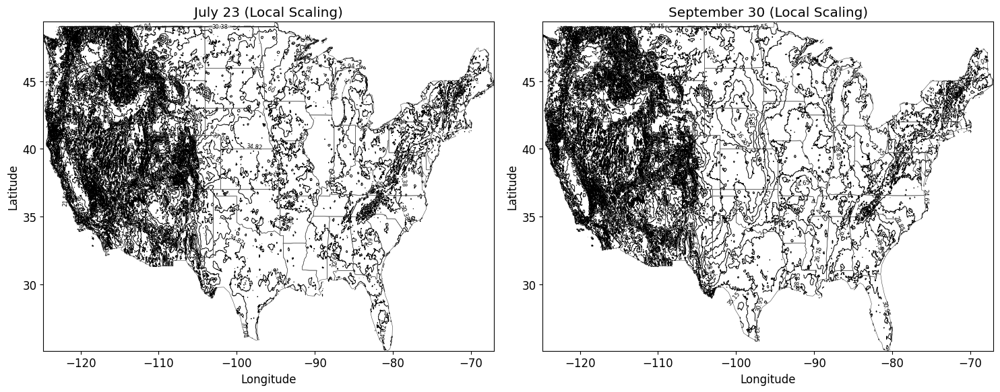

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

days = [
    (day_hot, "July 23"),
    (day_cool, "September 30")
]

for ax, (data, title) in zip(axes, days):

    local_levels = np.linspace(
        float(data.min()),
        float(data.max()),
        20
    )

    cs = ax.contour(
        lon,
        lat,
        data,
        levels=local_levels,
        colors="black",
        linewidths=0.7
    )

    ax.clabel(cs, fontsize=6)

    add_states(ax)
    ax.set_title(title + " (Local Scaling)")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.gcf().savefig('figures/local_lines.png', dpi=200, bbox_inches='tight')
plt.show()

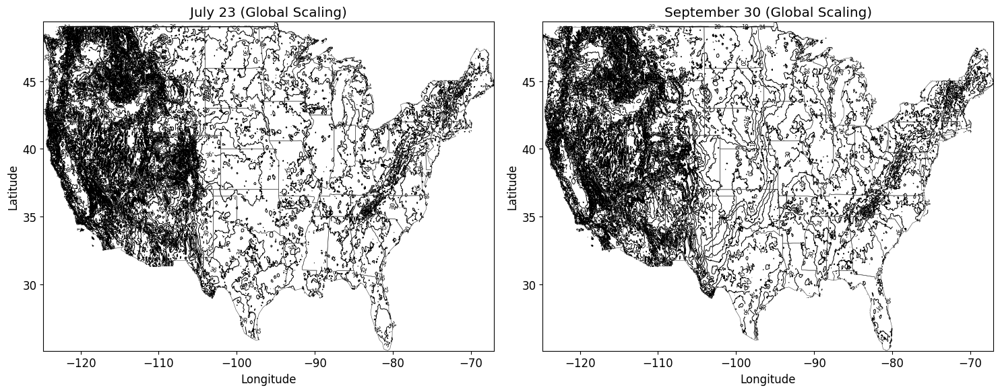

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

days = [
    (day_hot, "July 23"),
    (day_cool, "September 30")
]

for ax, (data, title) in zip(axes, days):

    cs = ax.contour(
        lon,
        lat,
        data,
        levels=global_levels,
        colors="black",
        linewidths=0.7
    )

    ax.clabel(cs, fontsize=6)

    add_states(ax)
    ax.set_title(title + " (Global Scaling)")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.gcf().savefig('figures/global_lines.png', dpi=200, bbox_inches='tight')
plt.show()

**Note on the two line-only comparisons above:** they show how contour spacing changes with scaling but have no colour, so they cannot show colour comparability. The comparison of global and local scaling is made with the filled maps below (`final_contours/tmmx_*.png` vs `tmmx_local_*.png`).

# Global Scaling
- Uses one common minimum and maximum value for both July 23 and September 30.
- This makes the colors/contours directly comparable across dates.
# Local Scaling
- Each day uses its own minimum and maximum.
- This enhances the variation within each individual day.

NaN check -> raw min/max: 9.350000000000023 47.450000000000045 | smoothed min/max: 11.914805511840044 46.783996744986666


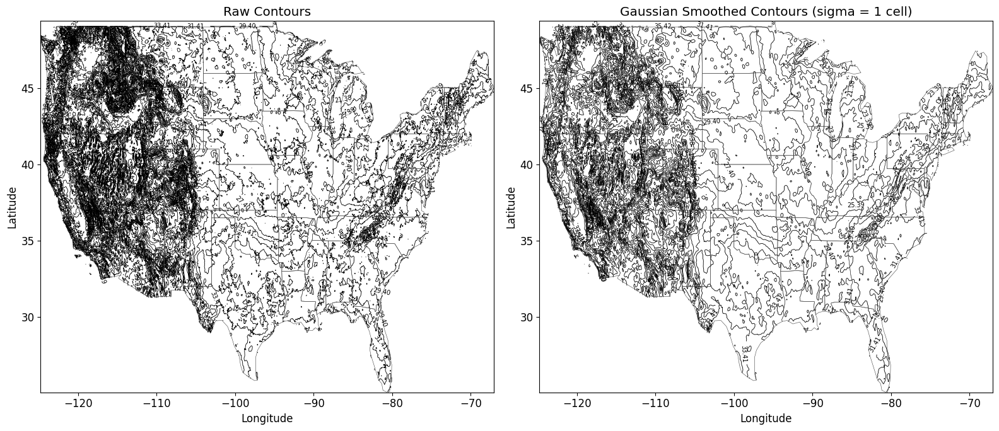

In [28]:
def smooth_nan(arr, sigma):
    """Gaussian smoothing that ignores NaN (ocean). Plain gaussian_filter turns the
    whole array into NaN as soon as one cell is NaN."""
    arr = np.asarray(arr, dtype=float)
    ok = np.isfinite(arr)
    num = gaussian_filter(np.where(ok, arr, 0.0), sigma)
    den = gaussian_filter(ok.astype(float), sigma)
    out = np.where(ok & (den > 1e-6), num / np.maximum(den, 1e-6), np.nan)
    return out

smooth_day = smooth_nan(day.values, sigma=1)
print("NaN check -> raw min/max:", np.nanmin(day.values), np.nanmax(day.values),
      "| smoothed min/max:", np.nanmin(smooth_day), np.nanmax(smooth_day))

levels = np.linspace(float(day.min()), float(day.max()), 20)

fig, ax = plt.subplots(1, 2, figsize=(16, 7))

c1 = ax[0].contour(lon, lat, day, levels=levels, colors="black", linewidths=0.6)
ax[0].clabel(c1, fontsize=7)
ax[0].set_title("Raw Contours")

c2 = ax[1].contour(lon, lat, smooth_day, levels=levels, colors="black", linewidths=0.6)
ax[1].clabel(c2, fontsize=7)
ax[1].set_title("Gaussian Smoothed Contours (sigma = 1 cell)")

for a in ax:
    add_states(a)
    a.set_xlabel("Longitude")
    a.set_ylabel("Latitude")

plt.tight_layout()
plt.gcf().savefig('figures/raw_vs_smoothed.png', dpi=200, bbox_inches='tight')
plt.show()

**What smoothing changes:** the raw field has small closed loops and jagged lines caused by grid-scale variation (mostly terrain). With sigma = 1 cell (about 4 km) those small loops disappear, but the large-scale pattern (hot Southwest, cooler north and mountains) stays the same. The smoothed field's minimum is higher (about 11.9 °C vs 9.35 °C) and its maximum lower (about 46.8 °C vs 47.45 °C), because smoothing slightly flattens single-cell extremes. Only a small amount is used so that real features are not removed.

# Colormap choice

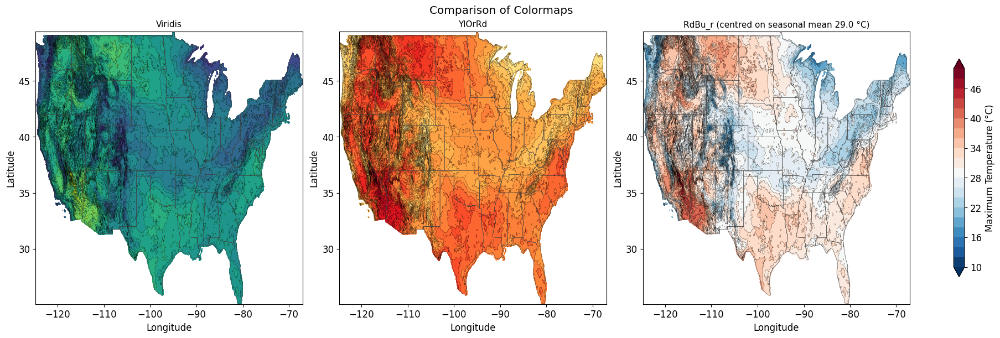

In [29]:
# Colormap comparison on the same day (Jul 1) with the same global levels.
# RdBu_r is only meaningful if its centre means something: centre it on the seasonal mean.
season_mean = float(temp_c.mean())
norm_div = TwoSlopeNorm(vmin=float(global_levels[0]), vcenter=season_mean, vmax=float(global_levels[-1]))

cmaps = [("viridis", None), ("YlOrRd", None), ("RdBu_r", norm_div)]
titles = ["Viridis", "YlOrRd", f"RdBu_r (centred on seasonal mean {season_mean:.1f} °C)"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)

for ax, (cmap, norm), title in zip(axes, cmaps, titles):
    cf = ax.contourf(lon, lat, day, levels=global_levels, cmap=cmap, norm=norm, extend="both")
    ax.contour(lon, lat, day, levels=global_levels, colors="black", linewidths=0.2)
    add_states(ax)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

fig.colorbar(cf, ax=axes, shrink=0.8, label="Maximum Temperature (°C)")
fig.suptitle("Comparison of Colormaps")
plt.gcf().savefig('figures/colormaps.png', dpi=200, bbox_inches='tight')
plt.show()

Viridis provides balanced visualization, YlOrRd emphasizes warmer temperatures, and RdBu_r clearly highlights regions that are above or below the seasonal average.

# Discrete bands vs continuous fill
Discrete bands (2°C): Temperature is grouped into fixed 2°C intervals, making different temperature zones easy to identify.

Continuous fill: Colors change smoothly with temperature, showing gradual spatial variations without visible bands.

Continuous fill + contour lines: Combines smooth color shading with contour lines every 5°C, making both temperature distribution and exact values easier to interpret.

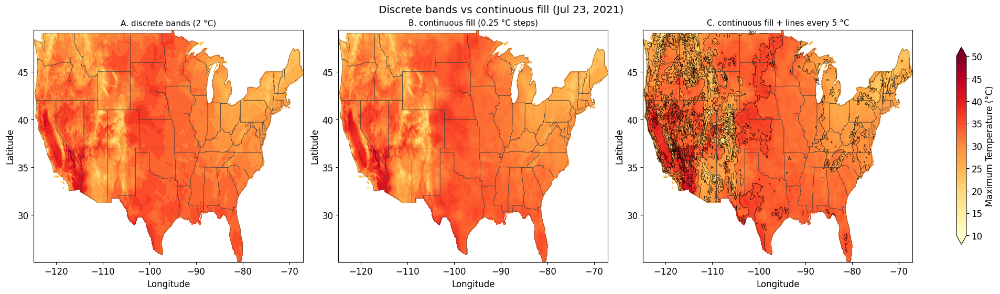

In [30]:
day_s = smooth_nan(day_hot.values, 1)          # hot day (Jul 23) shows the most structure
fine_levels = np.linspace(10, 50, 161)         # 0.25 degC steps -> reads as a continuous gradient
line_levels = np.arange(10, 55, 5)             # sparse lines every 5 degC

panels = [("A. discrete bands (2 °C)", global_levels, False),
          ("B. continuous fill (0.25 °C steps)", fine_levels, False),
          ("C. continuous fill + lines every 5 °C", fine_levels, True)]

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), constrained_layout=True)
for ax, (title, lv, lines) in zip(axes, panels):
    cf = ax.contourf(lon, lat, day_s, levels=lv, cmap="YlOrRd", extend="both")
    if lines:
        cs = ax.contour(lon, lat, day_s, levels=line_levels, colors="k", linewidths=0.5)
        ax.clabel(cs, fontsize=7, fmt="%d°")
    add_states(ax)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")

fig.colorbar(cf, ax=axes, ticks=line_levels, shrink=0.85, label="Maximum Temperature (°C)")
fig.suptitle("Discrete bands vs continuous fill (Jul 23, 2021)")
plt.gcf().savefig('figures/discrete_vs_continuous.png', dpi=200, bbox_inches='tight')
plt.show()

**Choice for the final maps:** panel C (continuous fill plus a few labelled lines) keeps the smooth colour change and still gives exact values from the lines. Panel A (2 °C bands) is easier for reading zones but looks blocky, and panel B has no way to read exact values. Panel C is used in all final maps.

In [31]:
# ---- Final map settings (decisions from the experiments above) ----
FINAL_CMAP   = "YlOrRd"                       # sequential colormap
FINAL_SIGMA  = 1                              # Gaussian sigma in grid cells; None = raw data
FILL_LEVELS  = np.linspace(10, 50, 161)       # fine levels -> continuous look
LINE_LEVELS  = np.arange(10, 55, 5)           # sparse labelled lines
EXTENT       = [-125, -66.5, 24.5, 49.5]      # lon_min, lon_max, lat_min, lat_max
OUT_DIR      = "final_contours"
os.makedirs(OUT_DIR, exist_ok=True)

# Check once that the border outlines can be loaded (they download on first use).
BORDERS_OK = False
if HAS_CARTOPY:
    try:
        list(cfeature.STATES.geometries()); list(cfeature.COASTLINE.geometries())
        BORDERS_OK = True
    except Exception as e:
        print("Could not load state/coast outlines (", type(e).__name__, ") - maps will have lat/lon grid only.")
print("cartopy:", HAS_CARTOPY, "| borders:", BORDERS_OK)

def new_map_axes(figsize=(11, 6)):
    if HAS_CARTOPY:
        fig, ax = plt.subplots(figsize=figsize, constrained_layout=True,
                               subplot_kw={"projection": ccrs.PlateCarree()})
    else:
        fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
    return fig, ax

def decorate_map(ax):
    if HAS_CARTOPY:
        ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
        if BORDERS_OK:
            ax.add_feature(cfeature.STATES, facecolor="none", edgecolor="0.25", linewidth=0.4, zorder=3)
            ax.add_feature(cfeature.COASTLINE, facecolor="none", edgecolor="0.1", linewidth=0.7, zorder=3)
        gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="0.4", alpha=0.4, linestyle="--")
        gl.top_labels = gl.right_labels = False
    else:
        ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3])
        ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")

def plot_local_contour(field_c, date_str):
    """Local scaling: colour range and line levels come from this day's own min/max."""
    field = smooth_nan(field_c.values, sigma=FINAL_SIGMA) if FINAL_SIGMA else field_c.values
    lo, hi = np.nanmin(field), np.nanmax(field)
    fill_levels = np.linspace(lo, hi, 161)
    line_levels = np.arange(5 * np.floor(lo / 5), 5 * np.ceil(hi / 5) + 5, 5)   # lines every 5 degC
    x, y = field_c["lon"].values, field_c["lat"].values
    kw = {"transform": ccrs.PlateCarree()} if HAS_CARTOPY else {}

    fig, ax = new_map_axes()
    cf = ax.contourf(x, y, field, levels=fill_levels, cmap=FINAL_CMAP, extend="both", zorder=1, **kw)
    cs = ax.contour(x, y, field, levels=line_levels, colors="k", linewidths=0.5, alpha=0.7, zorder=2, **kw)
    ax.clabel(cs, fmt="%d°", fontsize=7)
    decorate_map(ax)
    fig.colorbar(cf, ax=ax, ticks=line_levels, shrink=0.85, pad=0.02, label="Maximum Temperature (°C)")
    ax.set_title(f"Maximum Temperature, {date_str} (local scaling)")
    fig.savefig(f"{OUT_DIR}/tmmx_local_{date_str}.png", dpi=200)
    plt.show()
    plt.close(fig)

def plot_final_contour(field_c, date_str, title="Maximum Temperature", units="°C",
                       fill_levels=None, line_levels=None, cmap=None, line_fmt="%d°", prefix="tmmx"):
    """field_c: 2-D DataArray. Fixed levels + fixed figure geometry for every date, so the
    colour scale and layout never change between frames. Defaults are the tmmx settings above;
    other variables pass their own levels / units / colormap."""
    fill_levels = FILL_LEVELS if fill_levels is None else fill_levels
    line_levels = LINE_LEVELS if line_levels is None else line_levels
    cmap = FINAL_CMAP if cmap is None else cmap
    z = field_c.values
    if FINAL_SIGMA:
        z = smooth_nan(z, FINAL_SIGMA)
    x, y = field_c["lon"].values, field_c["lat"].values
    kw = {"transform": ccrs.PlateCarree()} if HAS_CARTOPY else {}

    fig, ax = new_map_axes()
    cf = ax.contourf(x, y, z, levels=fill_levels, cmap=cmap, extend="both", zorder=1, **kw)
    cs = ax.contour(x, y, z, levels=line_levels, colors="black", linewidths=0.5, alpha=0.7, zorder=2, **kw)
    ax.clabel(cs, fontsize=7, fmt=line_fmt)
    decorate_map(ax)
    fig.colorbar(cf, ax=ax, ticks=line_levels, shrink=0.85, pad=0.02, label=f"{title} ({units})")
    ax.set_title(f"{title}, {date_str}")

    # no bbox_inches="tight": identical pixel size for every frame (needed for a GIF)
    fig.savefig(f"{OUT_DIR}/{prefix}_{date_str}.png", dpi=200)
    plt.show()
    plt.close(fig)


cartopy: True | borders: True


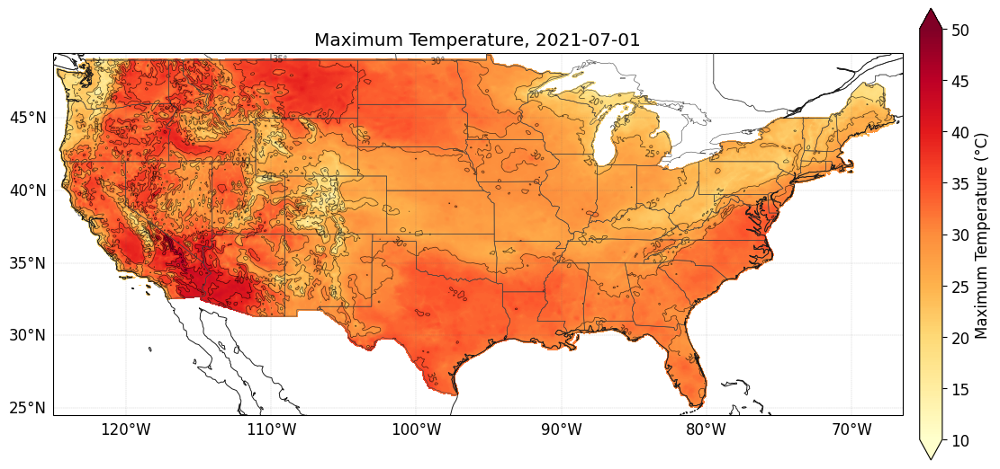

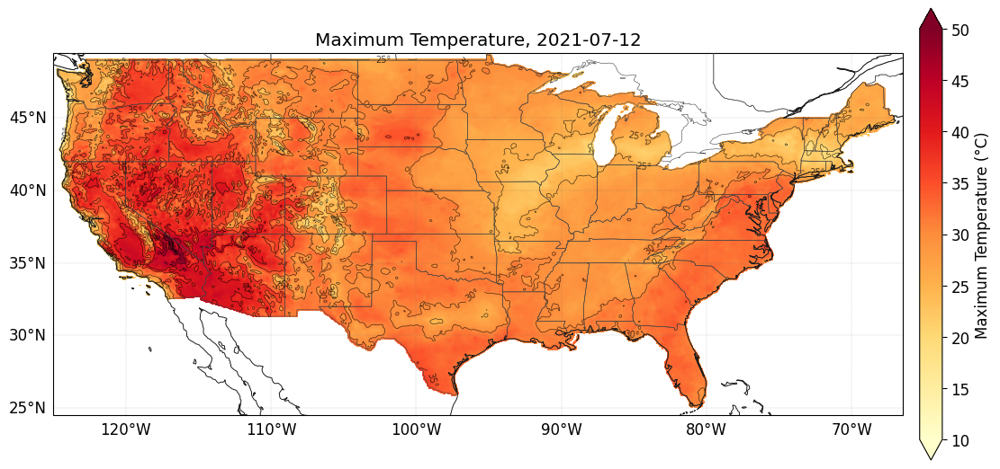

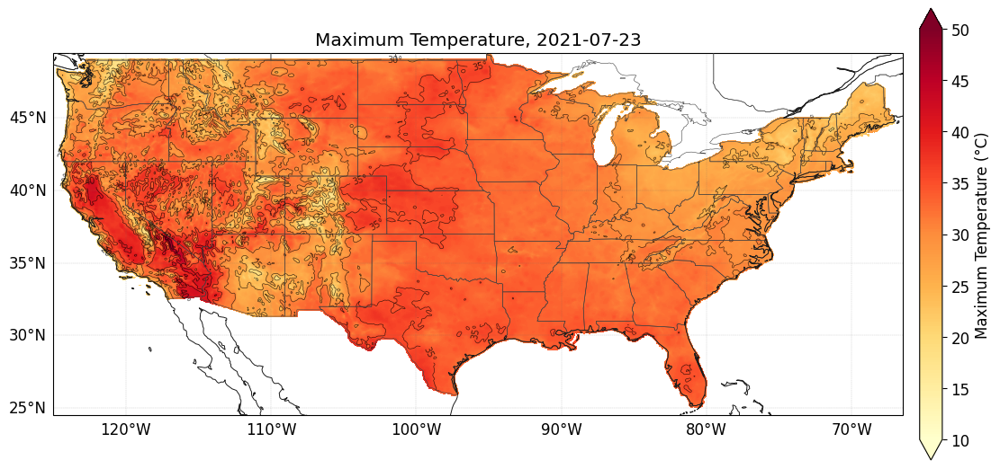

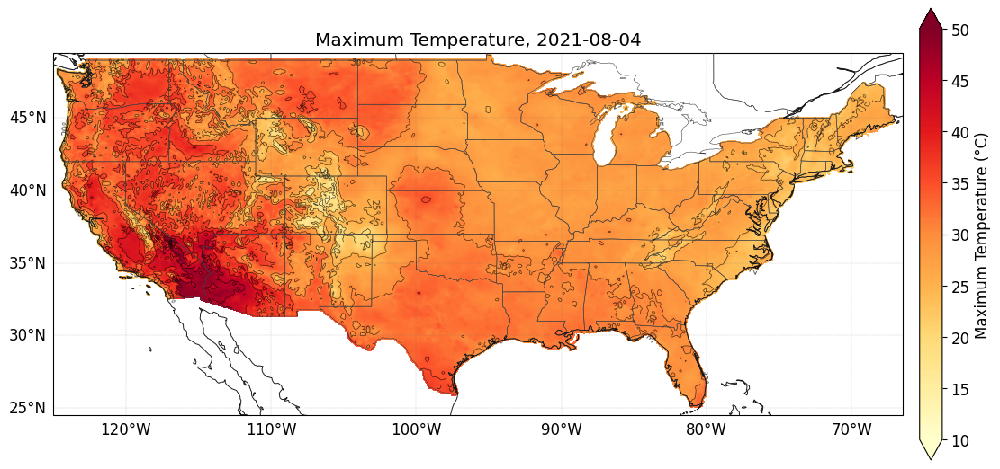

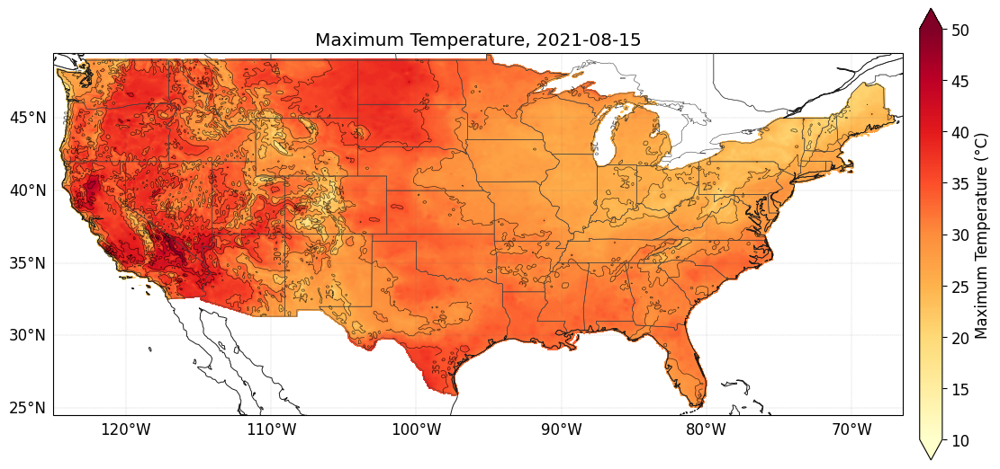

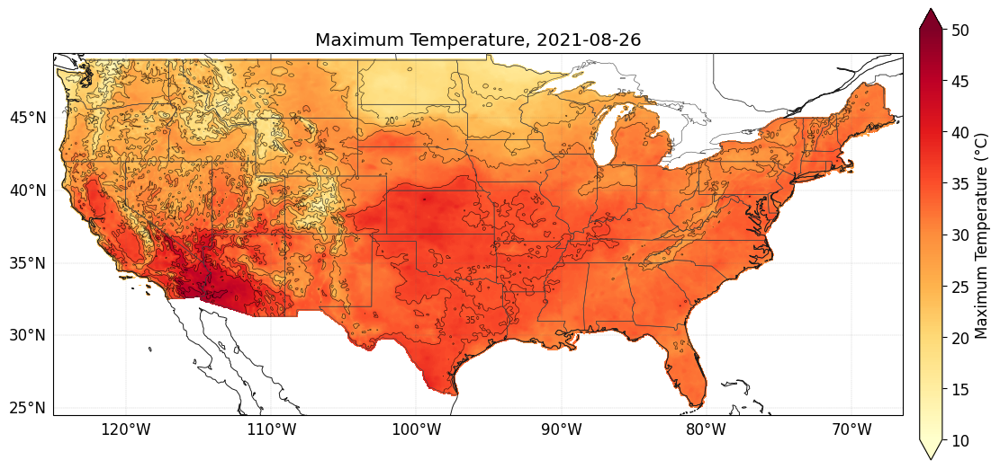

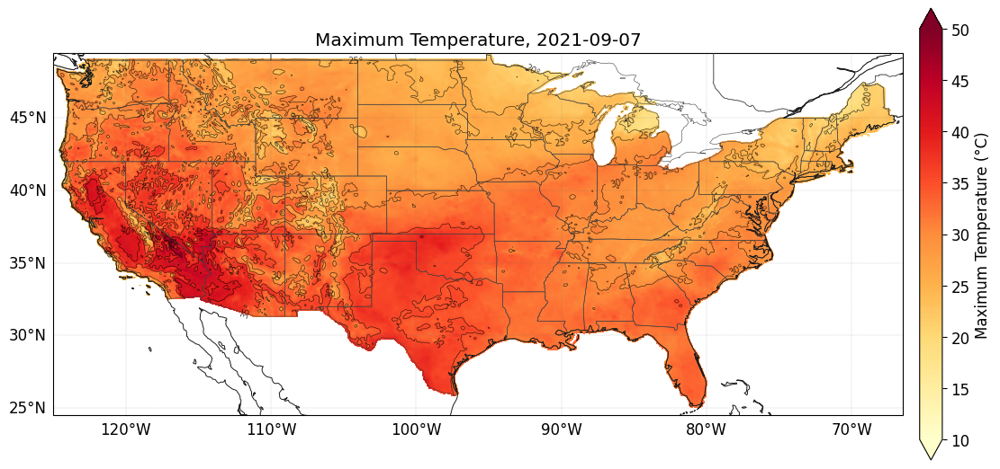

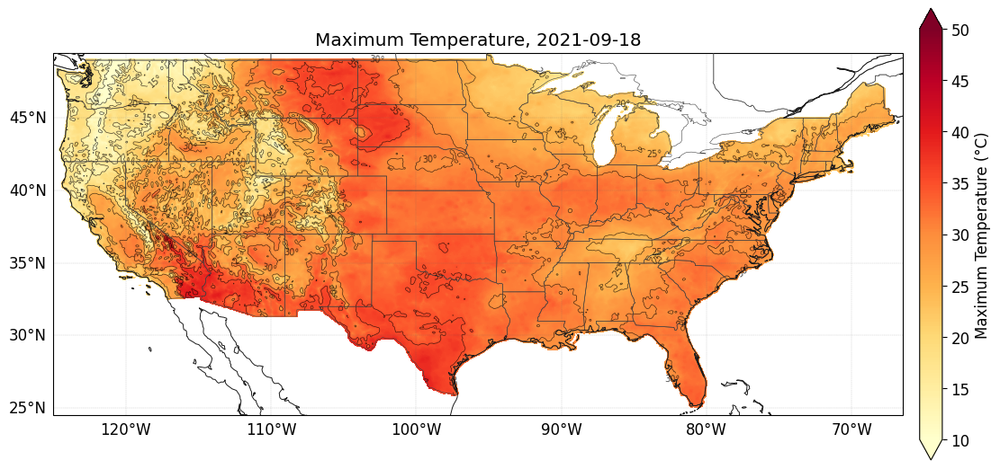

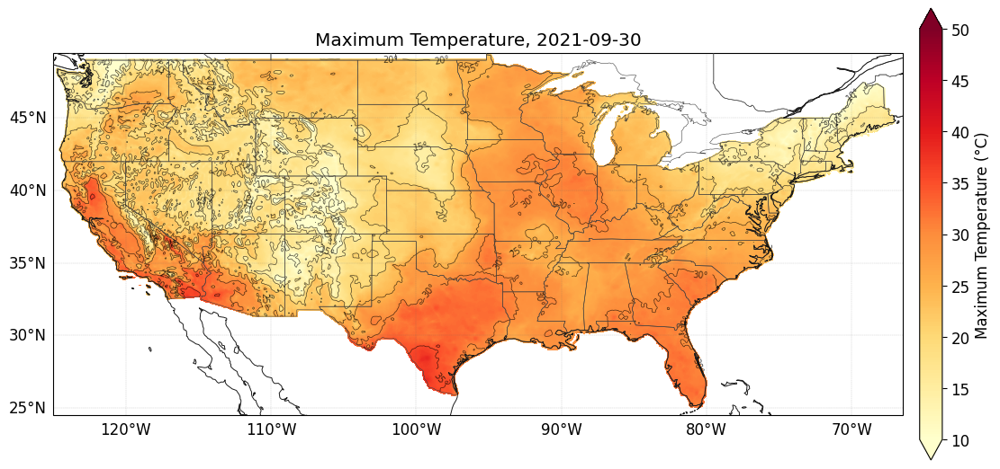

All global contour maps generated and saved to final_contours


In [32]:
# Uniform sample dates chosen earlier. temp_c is in degC, matching global_levels.
OUT_DIR = "final_contours"
for idx in uniform_idx:
    date_str = str(temp_c.day.values[idx])[:10]
    plot_final_contour(temp_c.isel(day=idx), date_str)

print("All global contour maps generated and saved to", OUT_DIR)

**Final maps (global scale, uniform dates):** all dates share one colour scale (10-50 °C), so colours can be compared across dates.
- **Jul 23:** values above 40 °C occur in the Southwest deserts and California's Central Valley. The Plains and Texas are mostly red (about 33-40 °C) and the East is cooler (about 25-32 °C).
- **Sep 30:** the heat has retreated. Values above about 35 °C remain only in south Texas and Southern California, Florida is about 30-32 °C and the central US about 28-32 °C. The northern Rockies, northern Plains and New England are mostly below 20 °C.
- Both dates: contour lines are densest over the western mountains, matching the steep elevation gradients.

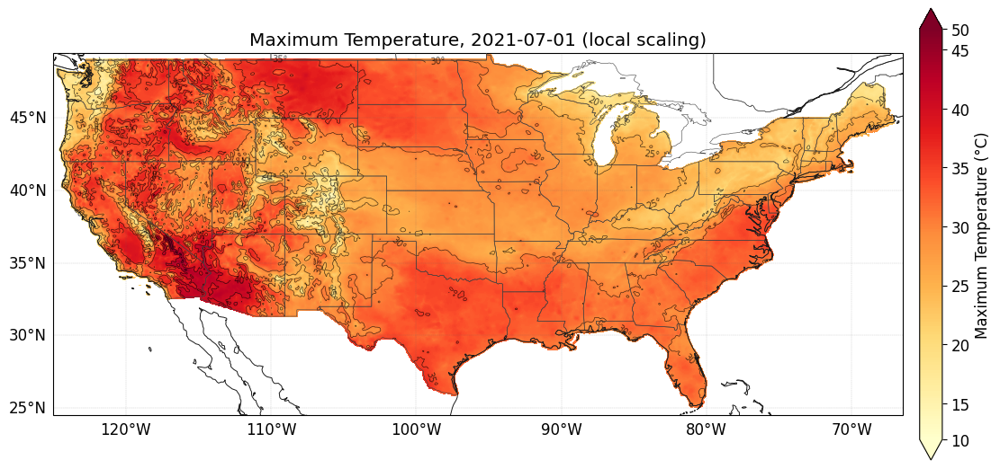

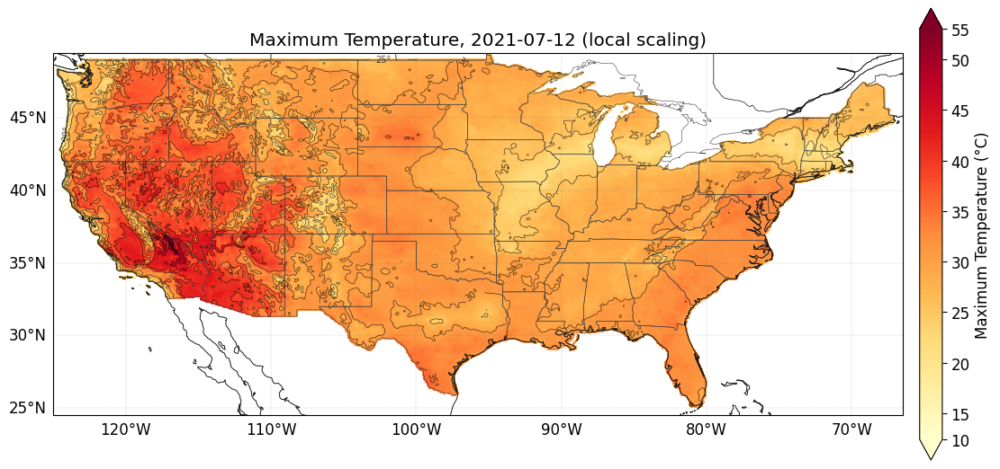

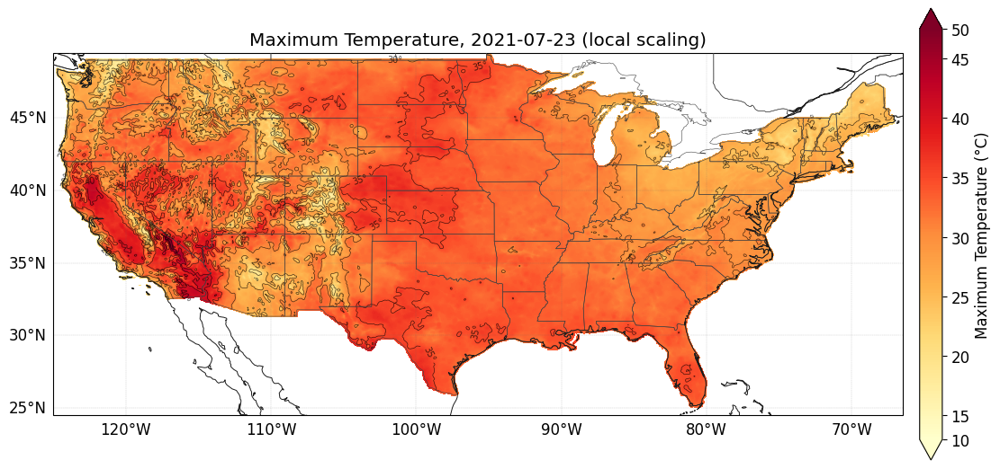

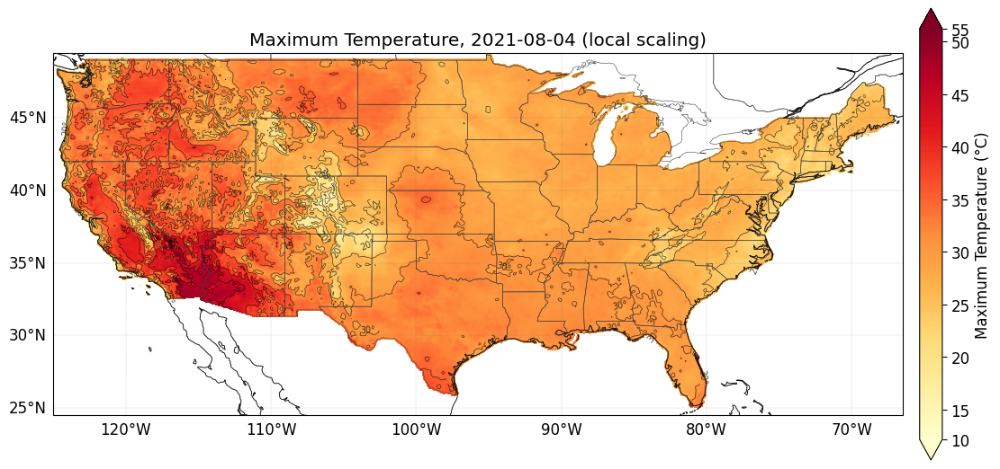

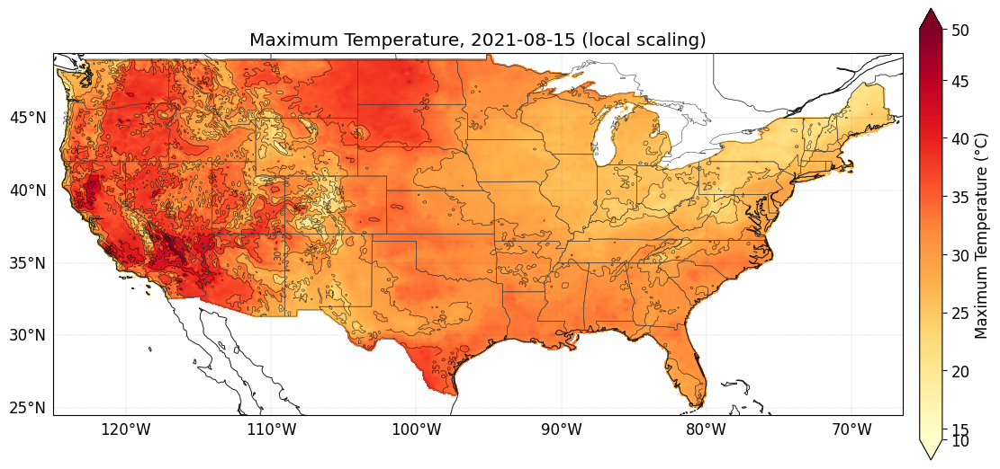

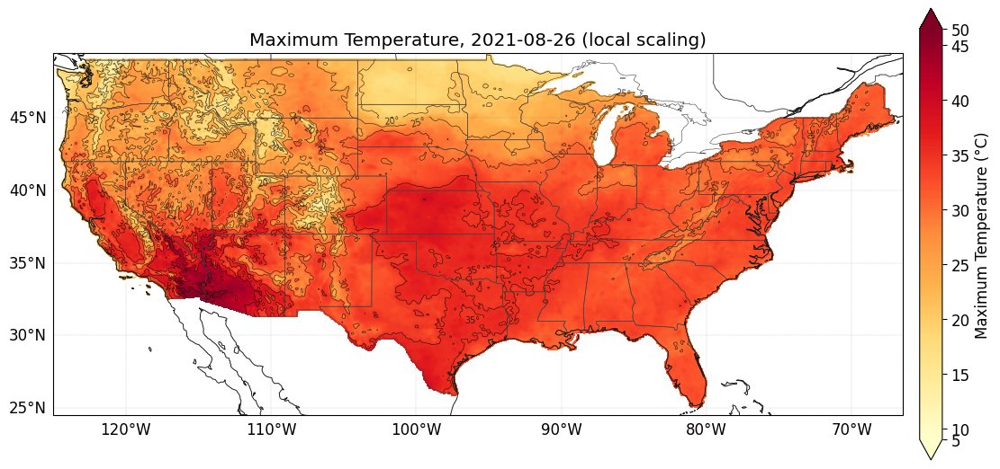

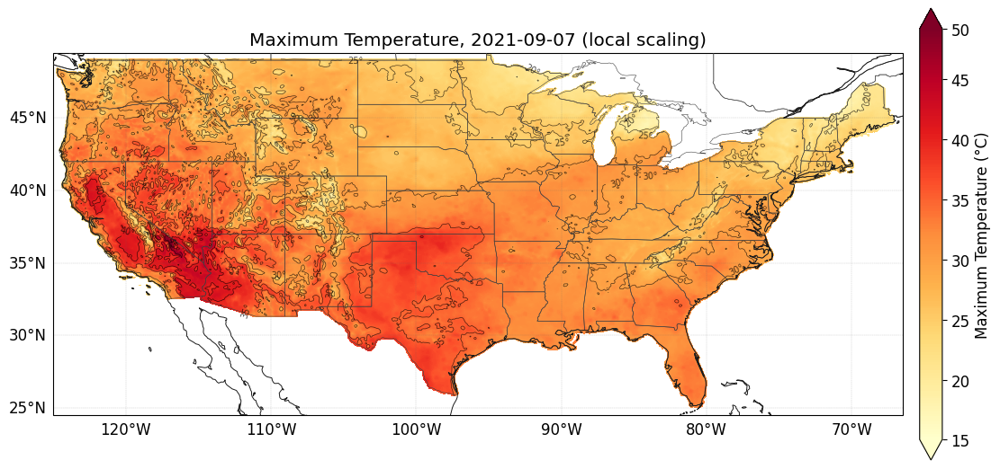

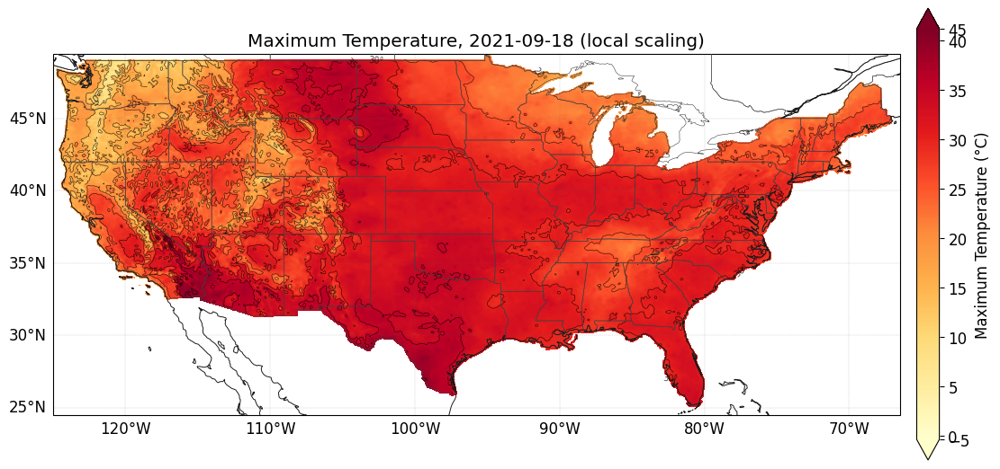

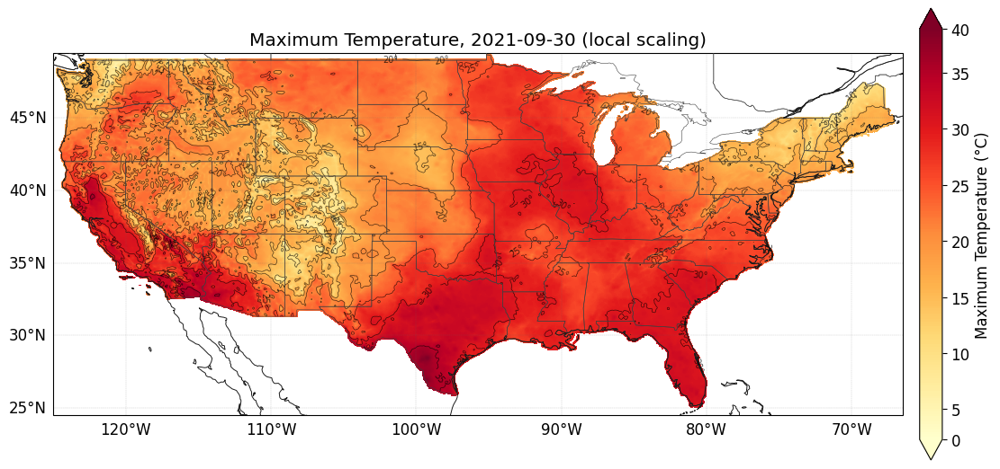

All local contour maps generated and saved to final_contours


In [33]:
OUT_DIR = "final_contours"
for idx in uniform_idx:
    date_str = str(temp_c.day.values[idx])[:10]
    plot_local_contour(temp_c.isel(day=idx), date_str)

print("All local contour maps generated and saved to", OUT_DIR)

**Local scaling:** each map uses its own minimum and maximum. This shows more spatial detail within a day (for example the structure in the Plains and Southeast on Sep 30), but colours are **not comparable between dates**: a cool Sep 30 map can look as dark as a hot July map. Use the global maps to compare dates and the local maps to study the pattern within one day.

**Supporting variables:** `tmmn`, `dtr`, `vpd` and `rmax` are shown for the first day of each month (Jul 1, Aug 1, Sep 1) to display the month-to-month change. These are snapshots for interpretation and are deliberately not the nine sampled dates; coordinate with the colour-map owner so that the same variable is not mapped by two members.

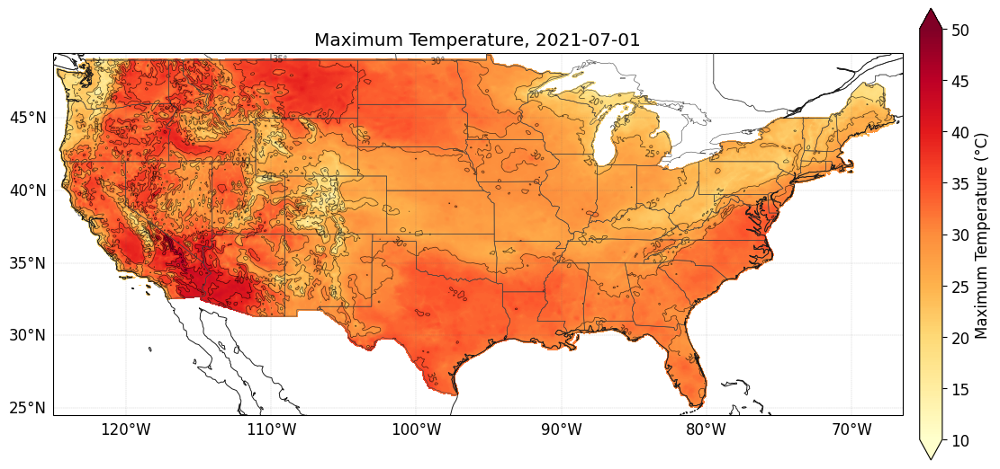

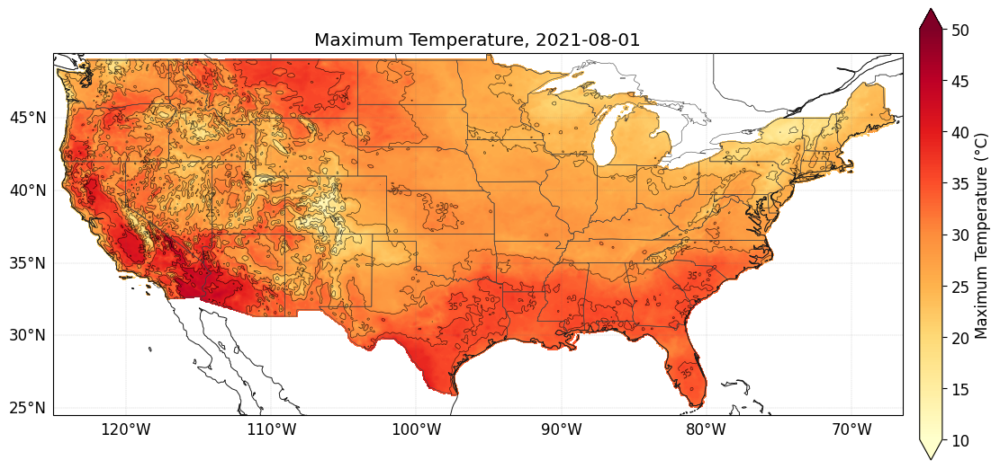

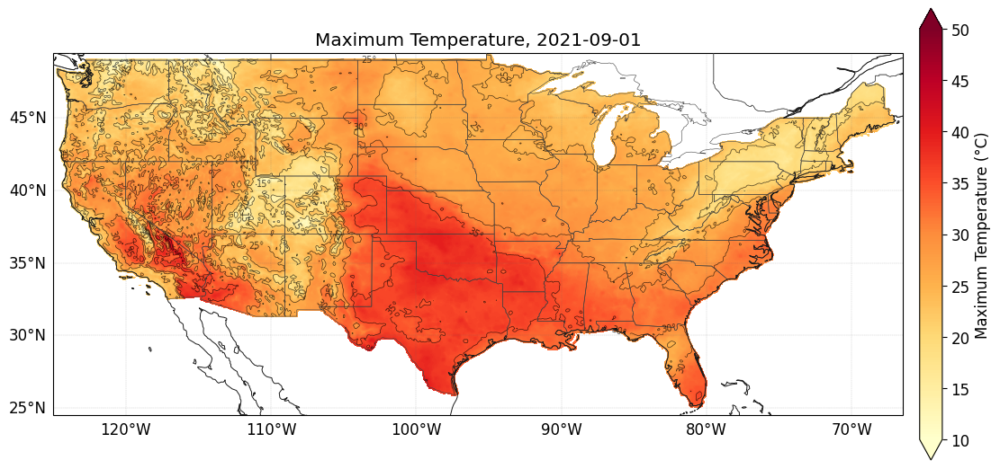

In [34]:
OUT_DIR = "seasonal_tmax"
os.makedirs(OUT_DIR, exist_ok=True)
months = [7, 8, 9]
for m in months:
    idx = np.where(temp_c.day.dt.month.values == m)[0][0]
    date_str = str(temp_c.day.values[idx])[:10]
    plot_final_contour(temp_c.isel(day=idx), date_str)

**Start-of-month maps (Jul 1, Aug 1, Sep 1):** the hottest areas move through the season. On Jul 1 the heat is in the West and Northwest (the end of the late-June 2021 Pacific Northwest heat wave) and the Southwest, while the East is more moderate. By August the heat is more widespread across the Plains and South, and by September the whole map has cooled.

# Supporting variables
The same final-map method is applied to three more gridMET variables for the same Jul-Sep 2021 window, to help explain the tmmx patterns: minimum temperature (`tmmn`), the diurnal temperature range (tmmx - tmmn), vapor pressure deficit (`vpd`) and maximum relative humidity (`rmax`). Each variable has its own units, so each needs its own colour levels (the 10-50 °C levels used for tmmx do not suit them).

In [35]:
import xarray as xr

tmin_ds = xr.open_dataset("data/tmmn_2021.nc")

print(tmin_ds)
print(list(tmin_ds.data_vars))

<xarray.Dataset> Size: 2GB
Dimensions:          (day: 365, lat: 585, lon: 1386, crs: 1)
Coordinates:
  * day              (day) datetime64[ns] 3kB 2021-01-01 ... 2021-12-31
  * lat              (lat) float64 5kB 49.4 49.36 49.32 ... 25.15 25.11 25.07
  * lon              (lon) float64 11kB -124.8 -124.7 -124.7 ... -67.1 -67.06
  * crs              (crs) uint16 2B 3
Data variables:
    air_temperature  (day, lat, lon) float64 2GB ...
Attributes: (12/19)
    geospatial_bounds_crs:      EPSG:4326
    Conventions:                CF-1.6
    geospatial_bounds:          POLYGON((-124.7666666333333 49.40000000000000...
    geospatial_lat_min:         25.066666666666666
    geospatial_lat_max:         49.40000000000000
    geospatial_lon_min:         -124.7666666333333
    ...                         ...
    date:                       30 March 2023
    note1:                      The projection information for this file is: ...
    note2:                      Citation: Abatzoglou, J.T., 2013, 

In [36]:
def season_levels(da, line_step):
    """Colour levels and line levels for one variable, from its own Jul-Sep range
    (0.5th-99.5th percentile of a subsample, so a few extreme cells don't stretch the scale)."""
    sample = da.values[:, ::5, ::5]
    lo, hi = np.nanpercentile(sample, [0.5, 99.5])
    lo = line_step * np.floor(lo / line_step)
    hi = line_step * np.ceil(hi / line_step)
    return np.linspace(lo, hi, 161), np.arange(lo, hi + line_step, line_step)

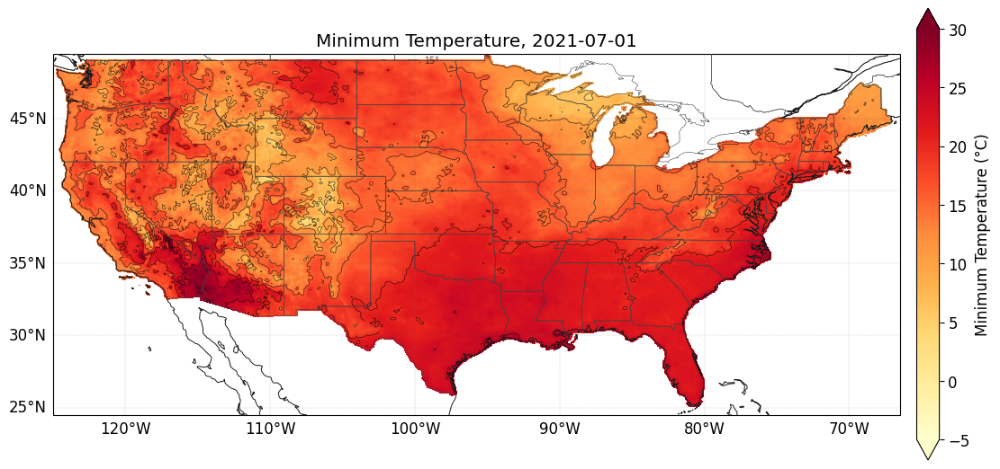

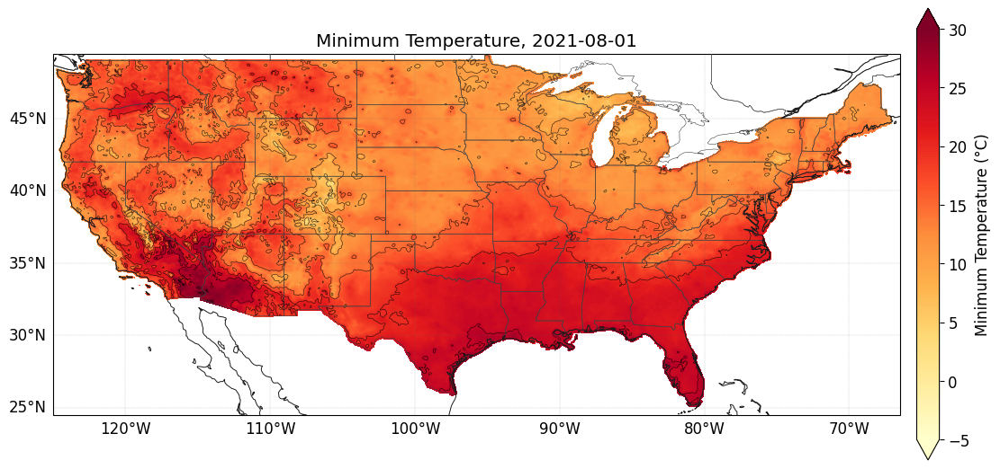

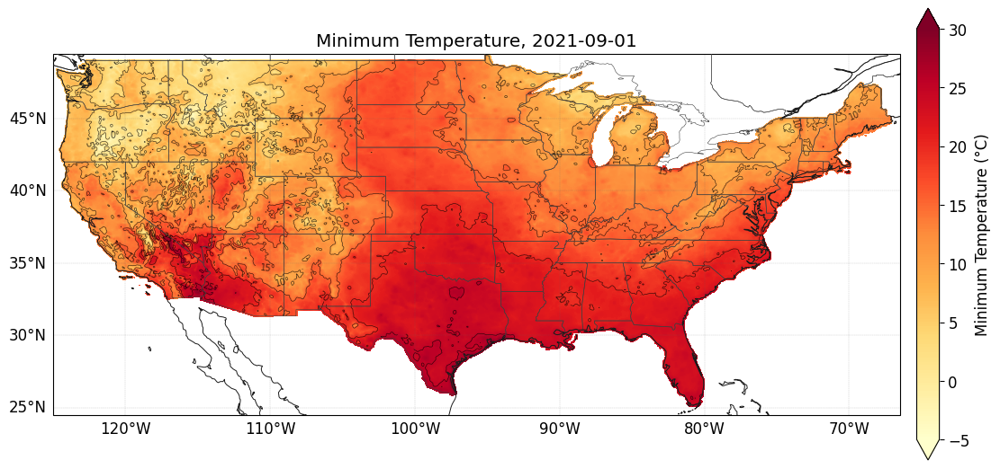

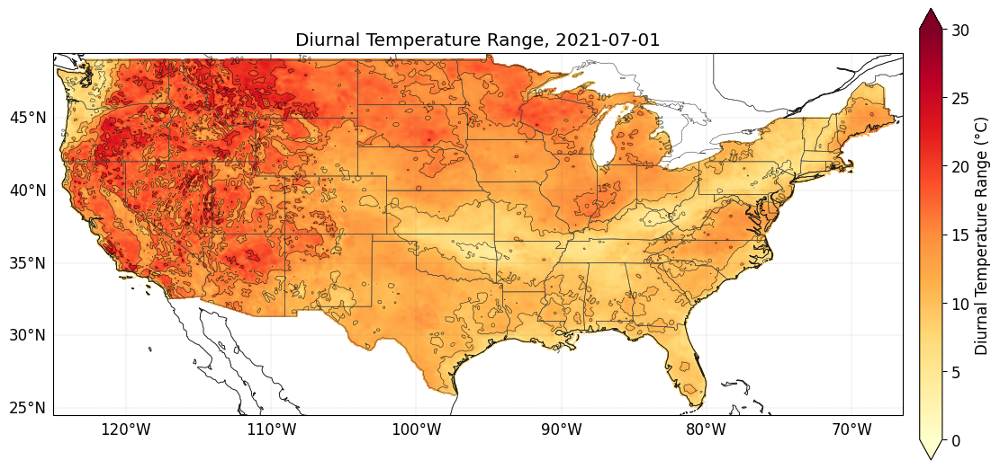

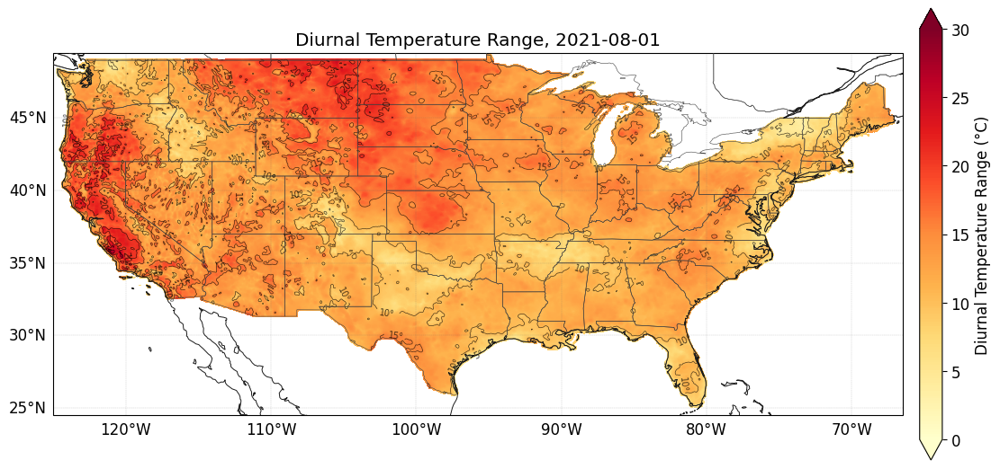

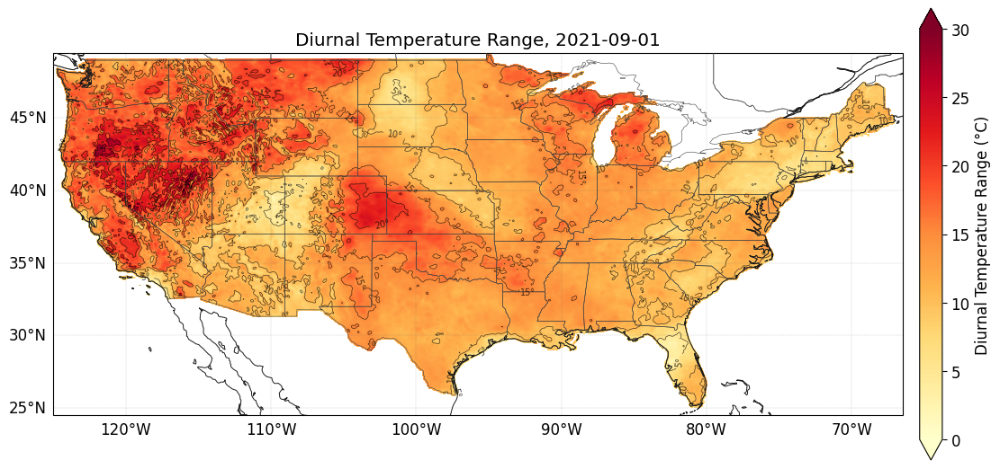

In [37]:
# Same Jul-Sep window as tmmx, so the two arrays align on the date coordinate.
tmin_c = tmin_ds["air_temperature"].sel(day=slice("2021-07-01", "2021-09-30")) - 273.15
dtr = temp_c - tmin_c          # diurnal temperature range = Tmax - Tmin (both in degC, same dates)
tmin_c.attrs["units"] = dtr.attrs["units"] = "degC"

OUT_DIR = "seasonal_tmin"
os.makedirs(OUT_DIR, exist_ok=True)
fl, ll = season_levels(tmin_c, 5)
for m in [7, 8, 9]:
    idx = np.where(tmin_c.day.dt.month.values == m)[0][0]
    date_str = str(tmin_c.day.values[idx])[:10]
    plot_final_contour(tmin_c.isel(day=idx), date_str, title="Minimum Temperature",
                       fill_levels=fl, line_levels=ll, prefix="tmmn")

OUT_DIR = "seasonal_dtr"
os.makedirs(OUT_DIR, exist_ok=True)
fl, ll = season_levels(dtr, 5)
for m in [7, 8, 9]:
    idx = np.where(dtr.day.dt.month.values == m)[0][0]
    date_str = str(dtr.day.values[idx])[:10]
    plot_final_contour(dtr.isel(day=idx), date_str, title="Diurnal Temperature Range",
                       fill_levels=fl, line_levels=ll, prefix="dtr")

**Minimum temperature (night-time) and diurnal range:**
- The warmest nights are along the Gulf Coast and Florida and in the low desert Southwest. The coolest nights are over the Rockies and the northern tier, so the minimum temperature varies with elevation and latitude.
- The diurnal range (Tmax - Tmin) is largest over the dry interior West and the Intermountain region, where the air is dry and the sky clear, so days heat up and nights cool down quickly. It is smallest in the humid Southeast and along coasts, where moisture and the ocean hold the temperature steady.
- This explains why the hottest tmmx areas (the dry Southwest) are not the areas with the warmest nights.

In [38]:
import xarray as xr

vpd_ds = xr.open_dataset("data/vpd_2021.nc")
print(vpd_ds)
print(list(vpd_ds.data_vars))

<xarray.Dataset> Size: 2GB
Dimensions:                      (day: 365, lat: 585, lon: 1386, crs: 1)
Coordinates:
  * day                          (day) datetime64[ns] 3kB 2021-01-01 ... 2021...
  * lat                          (lat) float64 5kB 49.4 49.36 ... 25.11 25.07
  * lon                          (lon) float64 11kB -124.8 -124.7 ... -67.06
  * crs                          (crs) uint16 2B 3
Data variables:
    mean_vapor_pressure_deficit  (day, lat, lon) float64 2GB ...
Attributes: (12/19)
    geospatial_bounds_crs:      EPSG:4326
    Conventions:                CF-1.6
    geospatial_bounds:          POLYGON((-124.7666666333333 49.40000000000000...
    geospatial_lat_min:         25.066666666666666
    geospatial_lat_max:         49.40000000000000
    geospatial_lon_min:         -124.7666666333333
    ...                         ...
    date:                       30 March 2023
    note1:                      The projection information for this file is: ...
    note2:            

In [39]:
vpd = vpd_ds["mean_vapor_pressure_deficit"].sel(day=slice("2021-07-01", "2021-09-30"))   # kPa

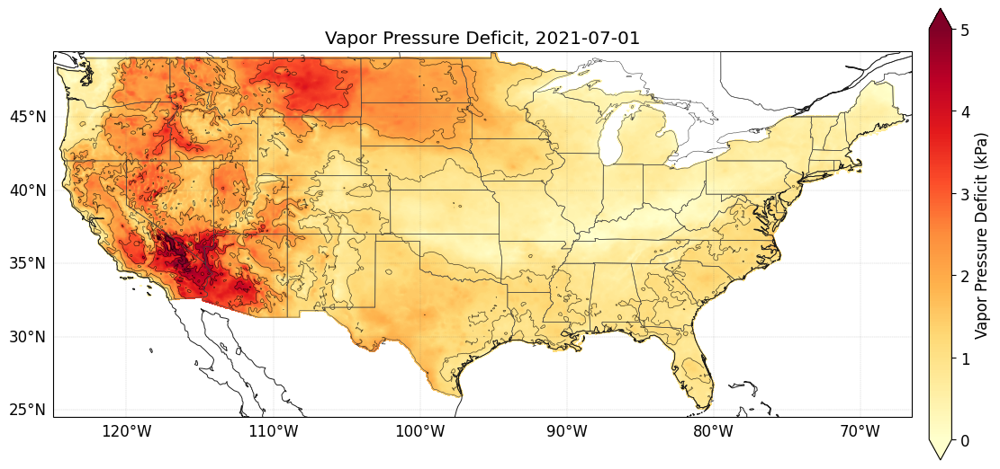

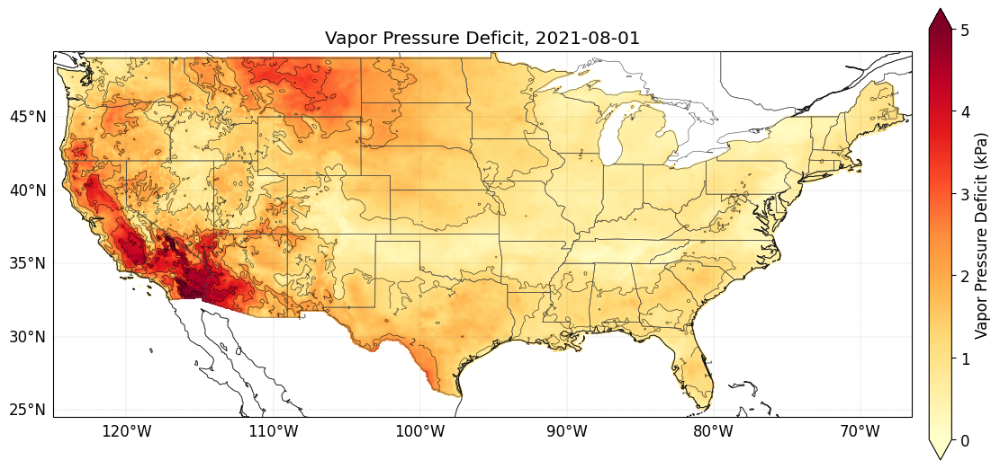

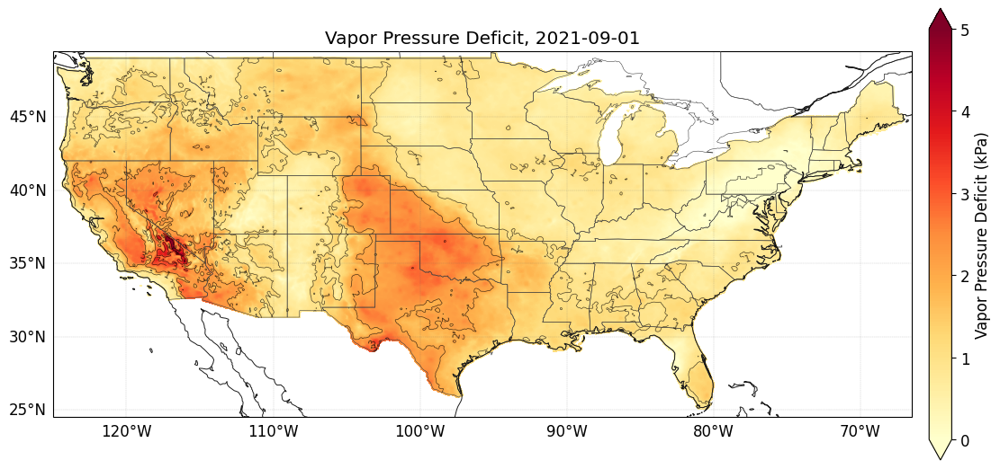

In [40]:
OUT_DIR = "seasonal_vpd"
os.makedirs(OUT_DIR, exist_ok=True)
fl, ll = season_levels(vpd, 1)          # lines every 1 kPa
for m in [7, 8, 9]:
    idx = np.where(vpd.day.dt.month.values == m)[0][0]
    date_str = str(vpd.day.values[idx])[:10]
    plot_final_contour(vpd.isel(day=idx), date_str, title="Vapor Pressure Deficit", units="kPa",
                       fill_levels=fl, line_levels=ll, line_fmt="%d", prefix="vpd")

**Vapor pressure deficit (kPa):** this is how much more moisture the air could hold, so it is the "thirstiness" of the air. VPD is highest over the arid Southwest and the Intermountain West, which overlap with the hottest tmmx regions, and lowest over the humid East, the Gulf Coast and the Pacific Northwest coast. VPD rises quickly with temperature, so its map looks like a sharpened version of the tmmx map. High VPD is the usual indicator for drought stress and wildfire risk.

In [41]:
rmax_ds = xr.open_dataset("data/rmax_2021.nc")
print(rmax_ds)
print(list(rmax_ds.data_vars))


<xarray.Dataset> Size: 2GB
Dimensions:            (day: 365, lat: 585, lon: 1386, crs: 1)
Coordinates:
  * day                (day) datetime64[ns] 3kB 2021-01-01 ... 2021-12-31
  * lat                (lat) float64 5kB 49.4 49.36 49.32 ... 25.15 25.11 25.07
  * lon                (lon) float64 11kB -124.8 -124.7 -124.7 ... -67.1 -67.06
  * crs                (crs) uint16 2B 3
Data variables:
    relative_humidity  (day, lat, lon) float64 2GB ...
Attributes: (12/19)
    geospatial_bounds_crs:      EPSG:4326
    Conventions:                CF-1.6
    geospatial_bounds:          POLYGON((-124.7666666333333 49.40000000000000...
    geospatial_lat_min:         25.066666666666666
    geospatial_lat_max:         49.40000000000000
    geospatial_lon_min:         -124.7666666333333
    ...                         ...
    date:                       30 March 2023
    note1:                      The projection information for this file is: ...
    note2:                      Citation: Abatzoglou, 

In [42]:
rmax = rmax_ds["relative_humidity"].sel(day=slice("2021-07-01", "2021-09-30"))   # percent

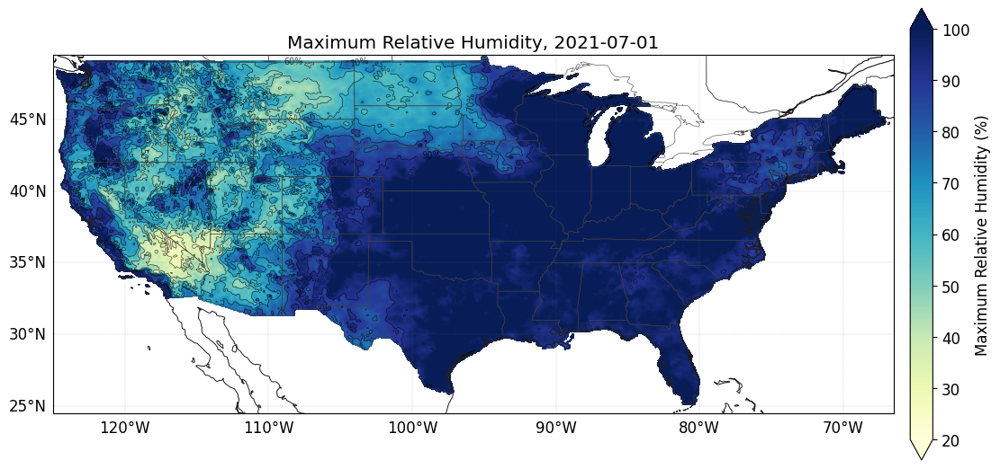

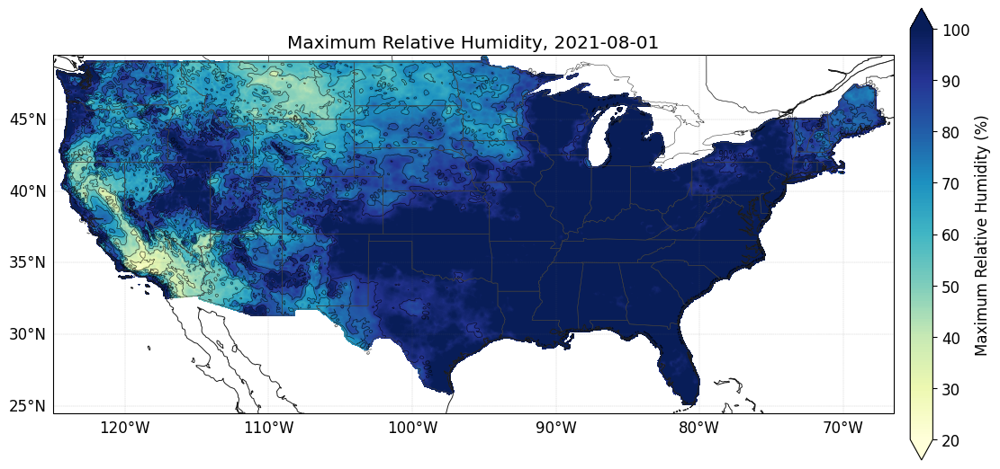

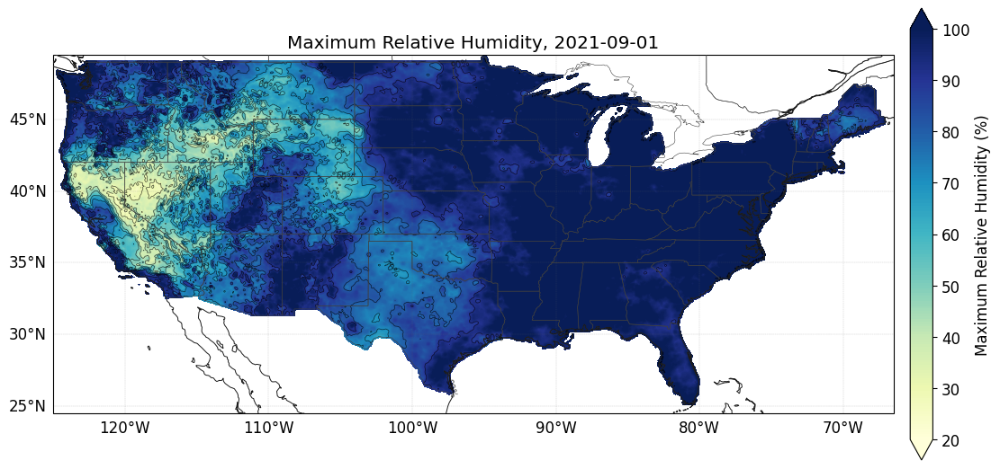

In [43]:
OUT_DIR = "seasonal_rmax"
os.makedirs(OUT_DIR, exist_ok=True)
fl, ll = season_levels(rmax, 10)        # lines every 10 %
for m in [7, 8, 9]:
    idx = np.where(rmax.day.dt.month.values == m)[0][0]
    date_str = str(rmax.day.values[idx])[:10]
    plot_final_contour(rmax.isel(day=idx), date_str, title="Maximum Relative Humidity", units="%",
                       fill_levels=fl, line_levels=ll, cmap="YlGnBu", line_fmt="%d%%", prefix="rmax")

**Maximum relative humidity (%):** the daily maximum (usually near dawn) is close to saturation over most of the country, so most of the map has one colour. The exceptions are the dry Southwest (southern California, Nevada, Arizona) and parts of the northern Rockies and Plains, where even the best part of the day stays well below saturation. This is the mirror image of the VPD map. Because of the saturation, the contrast comes mainly from these dry regions.

## Animation (GIF)
The final maps are saved with identical pixel size, so they can be stitched directly. One GIF is made with the global scale (comparable colours) and one with the local scale.

In [46]:
dates = [str(temp_c.day.values[i])[:10] for i in uniform_idx]       # the 9 uniformly sampled dates
for tag, pat in [("global", "final_contours/tmmx_{d}.png"), ("local", "final_contours/tmmx_local_{d}.png")]:
    frames = [imageio.imread(pat.format(d=d)) for d in dates]
    imageio.mimsave(f"tmmx_{tag}_scale.gif", frames, duration=1.2, loop=0)
    print("saved", f"tmmx_{tag}_scale.gif", len(frames), "frames")

saved tmmx_global_scale.gif 9 frames
saved tmmx_local_scale.gif 9 frames
